<a href="https://colab.research.google.com/github/mrcastilla8/Labs-Mineria/blob/master/Semana%2013/Breast_Cancer_Clasificacion_Laboratorio_Grupal_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio de Modelos de Clasificación — Ejercicio 3: Breast Cancer

**Plantilla de implementación grupal | Google Colab | Python 3**

Este notebook está **intencionalmente sin código implementado** en las secciones de trabajo. Cada integrante debe completar únicamente las celdas de código que le fueron asignadas y respetar los nombres de variables acordados. Las celdas de texto explican el trabajo requerido, sus dependencias y cómo comprobar que quedó listo.

> **Alcance acordado para el equipo (no es una instrucción adicional atribuida al profesor):** desarrollar el ejercicio original de clasificación de cáncer de mama de principio a fin, con exploración de datos, preprocesamiento, cinco clasificadores individuales y una comparación homogénea. No se incorporan por defecto los cuatro escaladores ni los cinco híbridos del Ejercicio 1 (Santander) porque **no se proporcionó esa indicación para este ejercicio**.

## Organización del trabajo

| Integrante | Secciones / subsecciones asignadas | Entrega principal |
|---|---|---|
| **Marco** *(coordinación)* | 0.1–0.2, 5.1, 5.5, 6.3 y 7.1 | Entorno, contratos, evaluación central, análisis de errores e integración final |
| **Poma** | 1.1–1.3, 5.2 | Carga, validación de datos, variables predictoras y tabla comparativa |
| **Aldana** | 2.1–2.3, 4.1, 5.4, 6.2 | EDA, regresión logística, curvas ROC e interpretación general |
| **Brickzon** | 3.1–3.3, 4.2–4.3 | División estratificada, escalamiento, KNN y SVM |
| **Vera** | 4.4–4.5, 5.3 y 6.1 | Árboles, matrices de confusión e importancia de variables |

**Orden de integración:** Marco (0) → Poma (1) → Aldana (2) → Brickzon (3) → modeladores (4) → responsables de evaluación (5) → cierre (6–7).

Se puede desarrollar código por separado, pero la versión integrada se debe ejecutar **de arriba abajo**, sin depender de variables ocultas de una sesión anterior.

## Descripción del conjunto de datos

Se utiliza el conjunto **Breast Cancer Wisconsin (Diagnostic)**. Las características proceden del análisis de imágenes digitalizadas de aspirados con aguja fina (FNA) y describen propiedades geométricas y de textura de los núcleos celulares.

- **Problema:** clasificación binaria supervisada; `M` = maligno y `B` = benigno.
- **Registros esperados:** 569, de los cuales 212 son malignos y 357 benignos.
- **Predictores:** 30 variables numéricas originales.
- **Fuente del experimento:** archivo `Semana 13/dataset/data.csv` del repositorio, cargado localmente o descargado desde un commit fijo cuando se abre en Colab.
- **Preparación:** se descartan `id` y posibles columnas vacías de exportación, nunca se usa `diagnosis` como predictor; se verifican las ausencias antes de la partición.
- **Referencia de origen:** [UCI Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

La codificación acordada es **1 = M (maligno, clase positiva)** y **0 = B (benigno)**. Esta convención debe mantenerse en predicciones, métricas, curvas ROC y matrices de confusión.

Este laboratorio es académico; sus predicciones **no constituyen diagnósticos clínicos**.


## Cómo ejecutar el notebook en Google Colab

1. Abre este `.ipynb` en Google Colab con **Python 3 (CPU)**; no se necesita GPU.
2. La sección **1.1 utiliza exclusivamente el CSV original** de la práctica. Primero busca `data.csv` en `/content/dataset/`, `dataset/` o `Semana 13/dataset/`.
3. Si el archivo no existe localmente, **1.1 lo descarga automáticamente del repositorio `mrcastilla8/Labs-Mineria` utilizando un commit fijo**, con lo que se evita cambiar silenciosamente a otra fuente. Requiere conexión y acceso de lectura al archivo; si falla, muestra un error y explica dónde cargarlo manualmente.
4. Usa **Entorno de ejecución → Reiniciar sesión y ejecutar todo**. Verifica en 1.1 la fuente `CSV original`, la huella SHA-256 y 569 registros antes de interpretar métricas.
5. Comprueba las cinco filas de `resultados_df`, los gráficos, las conclusiones y la sección 7.1. Los dos indicadores `PENDIENTE` de 7.1 representan comprobaciones que requieren auditoría humana, no fallos automáticos.

**Importante:** las salidas del experimento anterior se han retirado deliberadamente. Debes volver a ejecutar todas las celdas y guardar las nuevas evidencias con la fuente CSV. El notebook no ejecuta nada por sí mismo al abrirlo.


## 0. Preparación del entorno y acuerdos de integración

### 0.1. Librerías y configuración para Google Colab

**Responsable: Marco.**

**Qué debes hacer**

- Importa las librerías comunes: `pandas`, `numpy`, `matplotlib.pyplot`, `seaborn` y herramientas necesarias de `scikit-learn` para separación, transformación, modelos y métricas.
- Comprueba que el entorno usa Python 3 y que las dependencias están disponibles en Colab. Instala únicamente dependencias ausentes; evita instalar paquetes sin necesidad.
- Fija `RANDOM_STATE = 42` y una semilla global de NumPy para favorecer reproducibilidad. Define preferencias visuales legibles para figuras.

**Resultado esperado / criterio de aceptación**

Una ejecución limpia de esta celda deja listos los imports y `RANDOM_STATE`. No depende de ninguna celda posterior.

In [1]:
import sys

if sys.version_info.major != 3:
    raise RuntimeError("Este notebook requiere Python 3.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (8, 5), "axes.titlesize": 13,
                     "axes.labelsize": 11, "figure.dpi": 100})
print(f"Entorno listo: Python {sys.version_info.major}.{sys.version_info.minor}; RANDOM_STATE={RANDOM_STATE}")

Entorno listo: Python 3.13; RANDOM_STATE=42


### 0.2. Variables compartidas y registro de modelos

**Responsable: Marco.**

**Qué debes hacer**

- Declara los contenedores comunes `modelos_entrenados = {}` y `tipo_entrada = {}` antes del entrenamiento.
- Fija y comunica este contrato: `df_raw` = carga original; `df_clean` = columnas limpias; `X` = predictores numéricos; `y` = objetivo codificado con M=1/B=0; `X_train`, `X_test`, `y_train`, `y_test` = particiones; `escalador`, `X_train_scaled`, `X_test_scaled` = transformación ajustada solo en train.
- Cada responsable de un clasificador registrará `modelos_entrenados["Nombre del modelo"] = modelo_ajustado` y `tipo_entrada["Nombre del modelo"] = "escalado"` o `"original"`.
- Los nombres de modelo se acuerdan exactamente así: `Regresión logística`, `KNN`, `SVM`, `Árbol de decisión`, `Random Forest`.

**Resultado esperado / criterio de aceptación**

Existen dos diccionarios vacíos y el equipo conoce nombres y tipos. **No** crear aquí datos artificiales ni entrenar modelos.

In [2]:
# Contrato compartido: df_raw, df_clean, X, y, particiones y escalador
# son producidos por las subsecciones de datos y preprocesamiento asignadas.
modelos_entrenados = {}
tipo_entrada = {}
NOMBRES_MODELOS = (
    "Regresión logística", "KNN", "SVM", "Árbol de decisión", "Random Forest"
)
print("Registros de modelos inicializados. Convención objetivo: 1=M (maligno), 0=B (benigno).")

Registros de modelos inicializados. Convención objetivo: 1=M (maligno), 0=B (benigno).


## 1. Conjunto de datos

### 1.1. Carga del conjunto de datos

**Responsable: Poma.**

**Responsable: Poma — Carga reproducible del CSV original.**

- Busca el CSV en las ubicaciones del entorno; si no está en Colab, descárgalo desde el commit fijo del repositorio.
- No cambies la fuente a `sklearn.datasets.load_breast_cancer()` de manera silenciosa.
- Conserva `df_raw` y comprueba la columna `diagnosis`, las 569 filas, el origen visible y la huella SHA-256.

**Resultado esperado:** `df_raw` representa únicamente el CSV del ejercicio. El notebook se detiene con una indicación de carga manual si la descarga no está disponible.


In [3]:
# 1.1 — Carga reproducible del CSV original de la práctica.
# En Colab no se copia automáticamente el CSV al abrir este notebook desde GitHub.
from pathlib import Path
from urllib.request import urlopen
from IPython.display import display
import hashlib
import pandas as pd

rutas_csv = [
    Path("/content/dataset/data.csv"),
    Path("dataset/data.csv"),
    Path("Semana 13/dataset/data.csv"),
]
ruta_csv = next((ruta for ruta in rutas_csv if ruta.is_file()), None)

if ruta_csv is None:
    ruta_csv = Path("/content/dataset/data.csv")
    ruta_csv.parent.mkdir(parents=True, exist_ok=True)
    url_csv = "https://raw.githubusercontent.com/mrcastilla8/Labs-Mineria/53d12095b79a66e903b9608c203c1b929012260b/Semana%2013/dataset/data.csv"
    try:
        with urlopen(url_csv, timeout=30) as respuesta:
            contenido_csv = respuesta.read()
    except Exception as exc:
        raise RuntimeError(
            "No se pudo descargar el CSV original desde GitHub. "
            "Comprueba la conexión de Colab y el acceso al repositorio; "
            "o carga manualmente el archivo en /content/dataset/data.csv. "
            "No se sustituye silenciosamente por el dataset de sklearn."
        ) from exc
    if not contenido_csv:
        raise RuntimeError("La descarga del CSV devolvió un archivo vacío.")
    ruta_csv.write_bytes(contenido_csv)
    print("CSV original descargado del commit fijo: 53d12095b79a66e903b9608c203c1b929012260b")
else:
    print("CSV original encontrado localmente:", ruta_csv)

# Verificar el archivo completo, incluso si ya estaba cargado en /content.
# Git usa SHA-1 de: b"blob " + longitud + b"\0" + contenido.
bytes_csv = ruta_csv.read_bytes()
prefijo_git = b"blob " + str(len(bytes_csv)).encode("ascii") + bytes([0])
huella_git = hashlib.sha1(prefijo_git + bytes_csv).hexdigest()
if huella_git != "407af7079c9711633e3c9dcd773782023eff30f5":
    raise ValueError(
        "El archivo local no coincide con Semana 13/dataset/data.csv del commit fijado. "
        "Sustituye /content/dataset/data.csv por el CSV original del repositorio. "
        f"Git blob observado: {huella_git}"
    )

df_raw = pd.read_csv(ruta_csv)
if "diagnosis" not in df_raw.columns:
    raise ValueError("El CSV debe contener la columna diagnosis (M/B).")
if len(df_raw) != 569:
    raise ValueError(f"Se esperaban 569 registros del dataset original; se obtuvieron {len(df_raw)}.")

fuente_datos = f"CSV original: {ruta_csv}"
huella_csv = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
print(f"Fuente utilizada: {fuente_datos}")
print(f"SHA-256 del CSV: {huella_csv}")
print(f"Dimensiones originales: {df_raw.shape[0]} filas × {df_raw.shape[1]} columnas")
display(df_raw.head())


CSV original descargado del commit fijo: 53d12095b79a66e903b9608c203c1b929012260b
Fuente utilizada: CSV original: /content/dataset/data.csv
SHA-256 del CSV: 27f219231dbb30eecbfc1361407ed641ea01be43316e2c707a1baf82c9795e23
Dimensiones originales: 569 filas × 33 columnas


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### 1.2. Validación inicial y limpieza

**Responsable: Poma.**

**Qué debes hacer**

- Revisa tipos de datos, duplicados, valores nulos y distribución de las clases.
- Elimina columnas que no deben ser predictoras (`id`, `Unnamed: 32` u otras columnas enteramente vacías, si aparecen). Conserva `diagnosis` para formar el objetivo.
- Si existen ausentes, explica el criterio aplicado. Si se requiere imputación estadística, **no** calcules parámetros con el conjunto completo: esa imputación se debe ajustar usando únicamente entrenamiento en la sección 3.
- Guarda el resultado tabular en `df_clean`, sin modificar permanentemente `df_raw`.

**Resultado esperado / criterio de aceptación**

`df_clean` contiene `diagnosis` más las variables predictoras válidas. Reporta el antes/después y las decisiones de limpieza.

**Atención:** En caso de duplicados, justificar su tratamiento; no eliminar muestras automáticamente sin documentar por qué.

In [4]:
# 1.2 Validación inicial y limpieza sin alterar df_raw
import pandas as pd
from IPython.display import display

print("Dimensiones antes de limpiar:", df_raw.shape)
print("Tipos de datos originales:")
display(df_raw.dtypes.rename("tipo").to_frame())
print("Filas duplicadas exactas:", int(df_raw.duplicated().sum()))
print("Valores ausentes por columna (solo columnas con ausentes):")
ausentes = df_raw.isna().sum()
display(ausentes[ausentes.gt(0)].rename("ausentes").to_frame())
print("Distribución original de diagnosis:")
display(df_raw["diagnosis"].value_counts(dropna=False).rename("conteo").to_frame())

# Se trabaja sobre una copia. Los identificadores y columnas de exportación vacías
# no describen características y no deben entrar a X.
df_clean = df_raw.copy()
df_clean.columns = [str(col).strip() for col in df_clean.columns]
columnas_no_predictoras = [
    col for col in df_clean.columns
    if col.lower() == "id"
    or col.lower().startswith("unnamed:")
    or (col.lower() != "diagnosis" and df_clean[col].isna().all())
]
df_clean = df_clean.drop(columns=columnas_no_predictoras)

if "diagnosis" not in df_clean.columns:
    raise ValueError("No se encontró la columna diagnosis después de la limpieza.")
df_clean["diagnosis"] = df_clean["diagnosis"].astype("string").str.strip().str.upper()
if df_clean["diagnosis"].isna().any():
    raise ValueError("Hay diagnósticos ausentes; no se eliminan filas de forma silenciosa.")

etiquetas_observadas = set(df_clean["diagnosis"].unique())
if not etiquetas_observadas.issubset({"M", "B"}):
    raise ValueError(f"Etiquetas de diagnóstico inesperadas: {sorted(etiquetas_observadas)}")

print("Columnas eliminadas (ID/exportación):", columnas_no_predictoras or "ninguna")
print("Filas duplicadas conservadas para no descartar muestras sin justificación:", int(df_clean.duplicated().sum()))
print("Dimensiones después de limpiar:", df_clean.shape)
print("Valores ausentes restantes:", int(df_clean.isna().sum().sum()))
print("Criterio de ausentes: no imputar antes de la partición; si hubiera ausentes en predictores, la imputación debe ajustarse solo con train en 3.2.")


Dimensiones antes de limpiar: (569, 33)
Tipos de datos originales:


,tipo
id,int64
diagnosis,object
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave points_mean,float64


Filas duplicadas exactas: 0
Valores ausentes por columna (solo columnas con ausentes):


,ausentes
Unnamed: 32,569


Distribución original de diagnosis:


,conteo
diagnosis,
B,357
M,212


Columnas eliminadas (ID/exportación): ['id', 'Unnamed: 32']
Filas duplicadas conservadas para no descartar muestras sin justificación: 0
Dimensiones después de limpiar: (569, 31)
Valores ausentes restantes: 0
Criterio de ausentes: no imputar antes de la partición; si hubiera ausentes en predictores, la imputación debe ajustarse solo con train en 3.2.


### 1.3. Selección de X e y y codificación del diagnóstico

**Responsable: Poma.**

**Qué debes hacer**

- Crea `y` desde `df_clean["diagnosis"]` usando la convención `M → 1` y `B → 0`. Si el objetivo ya está numérico, valida explícitamente su significado antes de convertirlo.
- Crea `X` con **solo** las 30 características predictoras numéricas; excluye diagnóstico, identificadores y campos derivados de la etiqueta.
- Valida que `X` y `y` tienen el mismo número de filas, que `X` no incluye el diagnóstico, que `y` contiene únicamente `{0, 1}` y que no hay infinitos ni textos en `X`.
- Muestra forma de `X`, conteo de `y` y lista de columnas predictoras.

**Resultado esperado / criterio de aceptación**

Se pueden usar `X` e `y` en todas las siguientes secciones. Debe quedar claro que **1 = maligno**.

In [5]:
# 1.3 Selección de predictores y codificación M=1 / B=0
import numpy as np
import pandas as pd

if "diagnosis" not in df_clean.columns:
    raise ValueError("df_clean debe contener diagnosis.")

# La etiqueta se mapea explícitamente; nunca se infiere desde una característica.
y = df_clean["diagnosis"].map({"M": 1, "B": 0}).astype("int64")
X = df_clean.drop(columns=["diagnosis"]).copy()

# El contrato del ejercicio requiere las 30 características numéricas originales.
columnas_no_numericas = X.select_dtypes(exclude=[np.number]).columns.tolist()
if columnas_no_numericas:
    raise TypeError(f"Predictores no numéricos detectados: {columnas_no_numericas}")
if X.shape[1] != 30:
    raise ValueError(f"Se esperaban 30 predictores; se encontraron {X.shape[1]}: {X.columns.tolist()}")

valores_X = X.to_numpy(dtype=float)
if len(X) != len(y):
    raise ValueError("X e y no tienen el mismo número de filas.")
if "diagnosis" in X.columns:
    raise AssertionError("La etiqueta no debe formar parte de X.")
if not set(y.unique()).issubset({0, 1}):
    raise ValueError("y debe contener únicamente 0 y 1.")
if np.isinf(valores_X).any():
    raise ValueError("X contiene valores infinitos; deben corregirse antes de entrenar.")

conteo_ausentes = X.isna().sum()
columnas_con_ausentes = conteo_ausentes[conteo_ausentes.gt(0)]
print("Codificación objetivo: 1 = M (maligno), 0 = B (benigno)")
print("Forma de X:", X.shape)
print(f"Valores ausentes en X: {int(conteo_ausentes.sum())}")
if not columnas_con_ausentes.empty:
    print("Ausentes por predictor:")
    display(columnas_con_ausentes.rename("ausentes").to_frame())
print("Los ausentes se reservan para imputación en 3.2, ajustada únicamente con X_train.")
print("Conteo de y (0=benigno, 1=maligno):")
display(y.value_counts().sort_index().rename(index={0: "0 = B", 1: "1 = M"}).rename("conteo").to_frame())
print("Predictores (30):")
print(X.columns.tolist())


Codificación objetivo: 1 = M (maligno), 0 = B (benigno)
Forma de X: (569, 30)
Valores ausentes en X: 0
Los ausentes se reservan para imputación en 3.2, ajustada únicamente con X_train.
Conteo de y (0=benigno, 1=maligno):


,conteo
diagnosis,
0 = B,357
1 = M,212


Predictores (30):
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


## 2. Análisis exploratorio de datos (EDA)

### 2.1. Distribución de clases y balance del objetivo

**Responsable: Aldana.**

**Qué debes hacer**

- Usa `y` para calcular frecuencias absolutas y relativas de benignos (0) y malignos (1).
- Presenta un gráfico de barras con etiquetas legibles y porcentajes.
- Escribe una conclusión breve sobre la diferencia de proporciones y por qué puede influir en Accuracy y Recall.

**Resultado esperado / criterio de aceptación**

Tabla o impresión de conteos + figura + interpretación de 2–4 líneas. No modificar `X` ni `y`.

,diagnostico,conteo,porcentaje
0,Benigno (B=0),357,62.74
1,Maligno (M=1),212,37.26


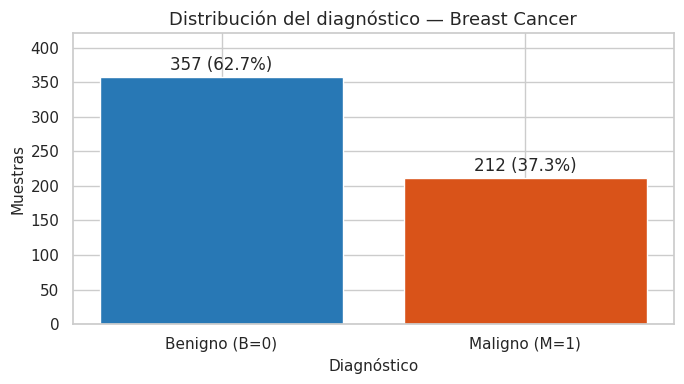

**Interpretación:** se observan 357 muestras benignas y 212 malignas (37.3% malignas). Predecir siempre la clase mayoritaria alcanzaría Accuracy=0.627. Predecir siempre benigno tendría Recall_M=0: la exactitud por sí sola puede ocultar malignos no detectados. Se deben revisar Recall_M, F1_M y falsos negativos.

In [6]:
# 2.1 — frecuencias absolutas y relativas del diagnóstico.
from IPython.display import display, Markdown

if not X.index.equals(y.index) or set(y.unique()) != {0, 1}:
    raise ValueError("EDA requiere X/y alineados y ambas clases: 0=B, 1=M.")
_etiquetas_eda = {0: "Benigno (B=0)", 1: "Maligno (M=1)"}
_colores_eda = {0: "#2878B5", 1: "#D95319"}
_conteos_eda = y.value_counts().reindex([0, 1], fill_value=0)
resumen_clases_eda = pd.DataFrame({
    "diagnostico": [_etiquetas_eda[c] for c in (0, 1)],
    "conteo": _conteos_eda.to_numpy(),
    "porcentaje": 100 * _conteos_eda.to_numpy() / len(y),
})
display(resumen_clases_eda.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
_barras_eda = ax.bar(resumen_clases_eda["diagnostico"], resumen_clases_eda["conteo"],
                     color=[_colores_eda[c] for c in (0, 1)])
for barra, porcentaje in zip(_barras_eda, resumen_clases_eda["porcentaje"]):
    ax.annotate(f"{int(barra.get_height())} ({porcentaje:.1f}%)",
                (barra.get_x() + barra.get_width()/2, barra.get_height()),
                xytext=(0, 5), textcoords="offset points", ha="center")
ax.set(title="Distribución del diagnóstico — Breast Cancer", ylabel="Muestras", xlabel="Diagnóstico")
ax.set_ylim(0, _conteos_eda.max() * 1.18)
fig.tight_layout()
plt.show()
proporcion_maligna_eda = float(y.mean())
accuracy_mayoritaria_eda = float(_conteos_eda.max() / len(y))
display(Markdown(
    f"**Interpretación:** se observan {int(_conteos_eda[0])} muestras benignas "
    f"y {int(_conteos_eda[1])} malignas ({100*proporcion_maligna_eda:.1f}% malignas). "
    f"Predecir siempre la clase mayoritaria alcanzaría Accuracy={accuracy_mayoritaria_eda:.3f}. "
    "Predecir siempre benigno tendría Recall_M=0: la exactitud por sí sola puede ocultar "
    "malignos no detectados. Se deben revisar Recall_M, F1_M y falsos negativos."))
# EDA descriptivo del conjunto disponible: no se modifica X/y, no se seleccionan
# variables ni hiperparámetros con estas salidas, que incluyen futuras filas de test.


### 2.2. Estadísticas descriptivas y distribución de predictores

**Responsable: Aldana.**

**Qué debes hacer**

- Muestra estadísticas descriptivas de `X` e inspecciona rangos y posibles valores extremos.
- Genera histogramas y/o boxplots de **un conjunto razonado** de variables (por ejemplo, radio, área, textura y concavidad), sin saturar el notebook con 30 gráficos redundantes.
- Compara visualmente al menos dos variables entre diagnósticos benigno y maligno, manteniendo la convención de colores/etiquetas en cada gráfico.
- Registra hallazgos observables, sin afirmar causalidad.

**Resultado esperado / criterio de aceptación**

Estadísticas descriptivas, gráficos legibles y conclusiones breves sobre variabilidad y diferencias visuales.

,count,mean,std,min,25%,50%,75%,max,ausentes,fuera_1_5_IQR
radius_mean,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100,0,14
texture_mean,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800,0,7
perimeter_mean,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000,0,13
area_mean,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000,0,25
smoothness_mean,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634,0,6
compactness_mean,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454,0,16
concavity_mean,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268,0,18
concave points_mean,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012,0,10
symmetry_mean,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040,0,15
fractal_dimension_mean,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974,0,15


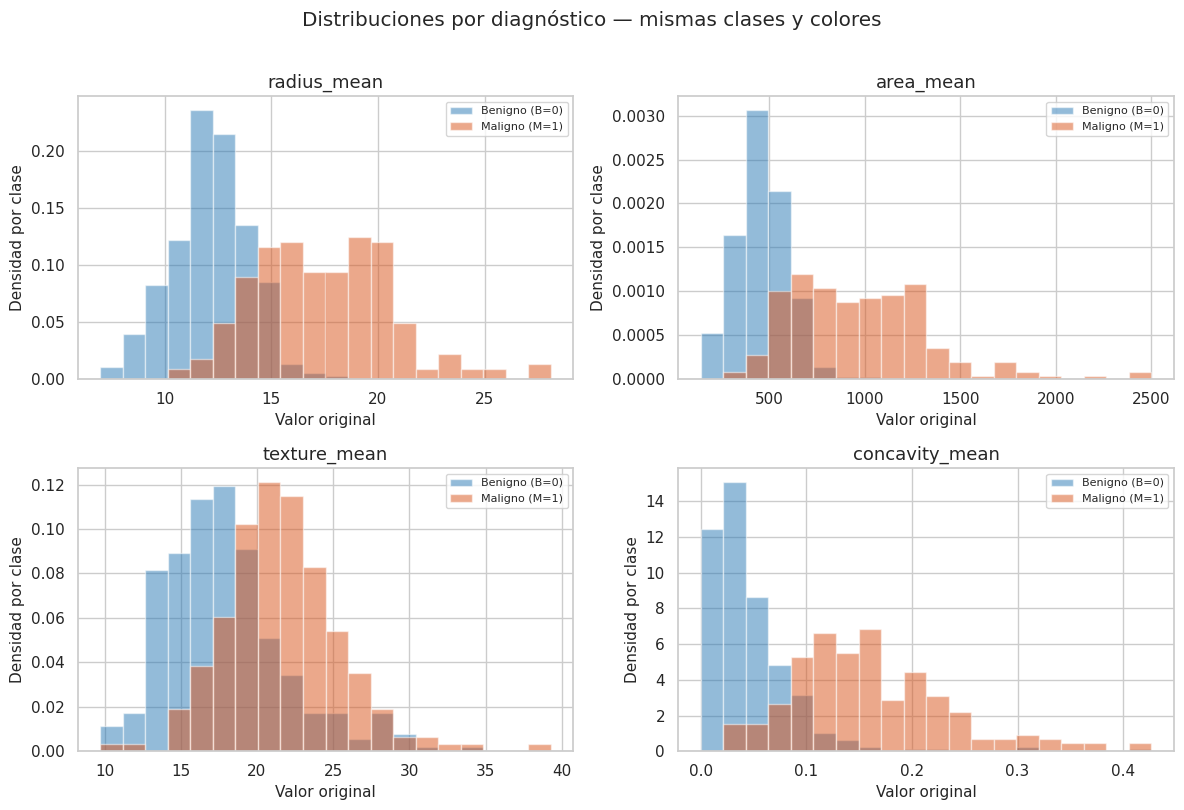

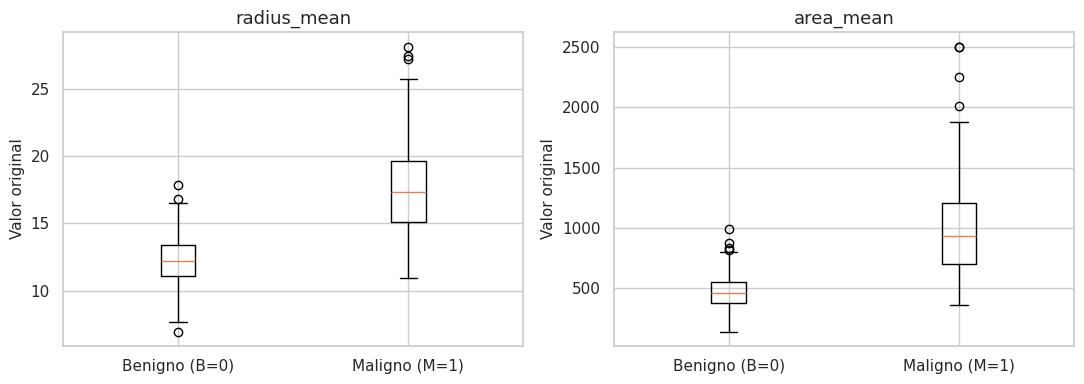

,radius_mean,area_mean,texture_mean,concavity_mean
diagnosis,,,,
Benigno (B=0),12.200,458.4,17.39,0.0371
Maligno (M=1),17.325,932.0,21.46,0.1513


**Hallazgos observados:** radius_mean: mediana B=12.2, M=17.33; area_mean: mediana B=458.4, M=932; texture_mean: mediana B=17.39, M=21.46; concavity_mean: mediana B=0.03709, M=0.1513. Los histogramas permiten inspeccionar separación y solapamiento entre diagnósticos; diferencias de medianas no implican separación perfecta ni causalidad. Los rangos dependen de la unidad de cada predictor, lo que motiva escalar antes de modelos sensibles a la magnitud. Los puntos fuera de 1.5 IQR son candidatos a valores extremos, no errores demostrados: se conservan sin recorte ni imputación en el EDA.

In [7]:
# 2.2 — rangos, distribuciones y diferencias entre diagnósticos.
# Resolver ambas fuentes permitidas: nombres del CSV y nombres de sklearn.
def _columna_eda(nombre_csv, nombre_sklearn):
    for nombre in (nombre_csv, nombre_sklearn):
        if nombre in X.columns:
            return nombre
    raise KeyError(f"No se encontró {nombre_csv} ni {nombre_sklearn} en X.")

variables_eda = [
    _columna_eda("radius_mean", "mean radius"),
    _columna_eda("area_mean", "mean area"),
    _columna_eda("texture_mean", "mean texture"),
    _columna_eda("concavity_mean", "mean concavity"),
]
resumen_predictoras_eda = X.describe().T
_q1_eda, _q3_eda = X.quantile(0.25), X.quantile(0.75)
_iqr_eda = _q3_eda - _q1_eda
_extremos_eda = X.lt(_q1_eda - 1.5*_iqr_eda) | X.gt(_q3_eda + 1.5*_iqr_eda)
resumen_predictoras_eda["ausentes"] = X.isna().sum()
resumen_predictoras_eda["fuera_1_5_IQR"] = _extremos_eda.sum()
display(resumen_predictoras_eda.round(4))

# Radio y área describen tamaño; textura y concavidad aportan otras propiedades.
# Se conservan unidades originales, sin mezclar escalas en un mismo eje vertical.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, columna in zip(axes.ravel(), variables_eda):
    _valores_eda = X[columna].dropna()
    if _valores_eda.empty:
        ax.set_title(f"{columna}: sin valores observados")
        continue
    _bins_eda = np.histogram_bin_edges(_valores_eda, bins=20)
    for clase in (0, 1):
        valores = X.loc[y.eq(clase), columna].dropna()
        if not valores.empty:
            ax.hist(valores, bins=_bins_eda, density=True, alpha=0.5,
                    color=_colores_eda[clase], label=_etiquetas_eda[clase])
    ax.set(title=columna, xlabel="Valor original", ylabel="Densidad por clase")
    ax.legend(fontsize=8)
fig.suptitle("Distribuciones por diagnóstico — mismas clases y colores", y=1.01)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, columna in zip(axes, variables_eda[:2]):
    ax.boxplot([X.loc[y.eq(c), columna].dropna().to_numpy() for c in (0, 1)])
    ax.set_xticks([1, 2], [_etiquetas_eda[c] for c in (0, 1)])
    ax.set(title=columna, ylabel="Valor original")
fig.tight_layout()
plt.show()

medianas_por_diagnostico_eda = X[variables_eda].groupby(y).median().reindex([0, 1])
display(medianas_por_diagnostico_eda.rename(index=_etiquetas_eda).round(4))
_hallazgos_distribucion_eda = []
for columna in variables_eda:
    b, m = medianas_por_diagnostico_eda.loc[0, columna], medianas_por_diagnostico_eda.loc[1, columna]
    _hallazgos_distribucion_eda.append(f"{columna}: mediana B={b:.4g}, M={m:.4g}")
display(Markdown(
    "**Hallazgos observados:** " + "; ".join(_hallazgos_distribucion_eda) + ". "
    "Los histogramas permiten inspeccionar separación y solapamiento entre diagnósticos; "
    "diferencias de medianas no implican separación perfecta ni causalidad. Los rangos "
    "dependen de la unidad de cada predictor, lo que motiva escalar antes de modelos "
    "sensibles a la magnitud. Los puntos fuera de 1.5 IQR son candidatos a valores extremos, "
    "no errores demostrados: se conservan sin recorte ni imputación en el EDA."))


### 2.3. Correlación y posibles redundancias

**Responsable: Aldana.**

**Qué debes hacer**

- Calcula la matriz de correlación de las 30 características de `X`.
- Muestra un mapa de calor legible (completo o filtrado a correlaciones altas) e identifica algunos pares de variables correlacionadas.
- Explica cómo la multicolinealidad puede afectar la interpretación de algunos clasificadores, y aclara que correlación **no** implica causalidad.
- No elimines columnas todavía sin acordarlo con Poma y Brickzon.

**Resultado esperado / criterio de aceptación**

Visualización de correlación y explicación fundamentada de 2–4 hallazgos.

**Atención:** El EDA es exploratorio. Cualquier selección automática de variables dependiente de datos deberá ajustarse en entrenamiento, nunca usando test.

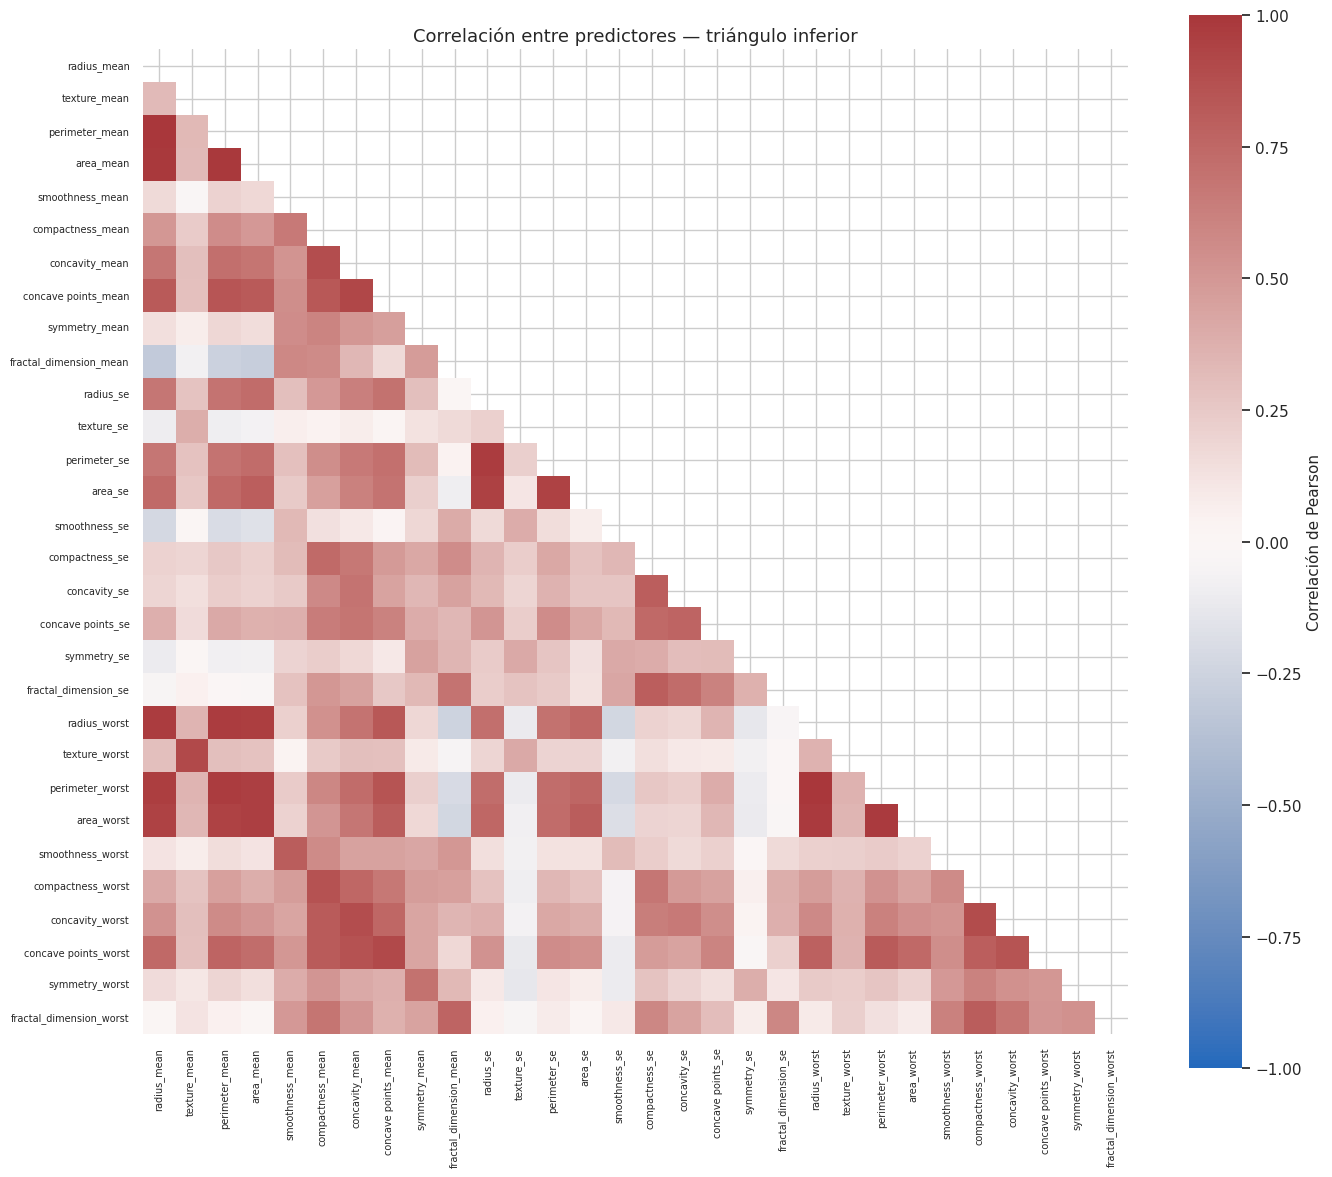

Diez pares con mayor correlación absoluta; sin diagonal ni pares duplicados:


,variable_1,variable_2,correlacion,correlacion_absoluta
0,radius_mean,perimeter_mean,0.9979,0.9979
1,radius_worst,perimeter_worst,0.9937,0.9937
2,radius_mean,area_mean,0.9874,0.9874
3,perimeter_mean,area_mean,0.9865,0.9865
4,radius_worst,area_worst,0.9840,0.9840
5,perimeter_worst,area_worst,0.9776,0.9776
6,radius_se,perimeter_se,0.9728,0.9728
7,perimeter_mean,perimeter_worst,0.9704,0.9704
8,radius_mean,radius_worst,0.9695,0.9695
9,perimeter_mean,radius_worst,0.9695,0.9695


**Interpretación:** hay 21 pares con |r|≥0.90. Los tres de mayor asociación son radius_mean / perimeter_mean: r=0.998; radius_worst / perimeter_worst: r=0.994; radius_mean / area_mean: r=0.987. Esto sugiere información compartida y posible redundancia. La multicolinealidad puede volver inestables los coeficientes individuales de regresión logística; su regularización L2 ayuda a estabilizar el ajuste, pero no convierte un coeficiente en un efecto causal. Pearson describe asociación lineal: una correlación pequeña no descarta relaciones no lineales. No se eliminan columnas; cualquier selección futura debe aprenderse solo dentro de entrenamiento.

In [8]:
# 2.3 — correlación de las 30 características, sin eliminarlas.
correlacion_eda = X.corr(method="pearson")
fig, ax = plt.subplots(figsize=(14, 12))
_mascara_eda = np.triu(np.ones(correlacion_eda.shape, dtype=bool))
sns.heatmap(correlacion_eda, mask=_mascara_eda, cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"label": "Correlación de Pearson"})
ax.set_title("Correlación entre predictores — triángulo inferior")
ax.tick_params(axis="both", labelsize=7)
plt.setp(ax.get_xticklabels(), rotation=90)
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

_triangulo_eda = np.triu(np.ones(correlacion_eda.shape, dtype=bool), k=1)
pares_correlacion_eda = (
    correlacion_eda.where(_triangulo_eda).stack().rename("correlacion")
    .rename_axis(["variable_1", "variable_2"]).reset_index()
)
pares_correlacion_eda["correlacion_absoluta"] = pares_correlacion_eda["correlacion"].abs()
pares_correlacion_eda = pares_correlacion_eda.sort_values(
    "correlacion_absoluta", ascending=False, kind="stable").reset_index(drop=True)
print("Diez pares con mayor correlación absoluta; sin diagonal ni pares duplicados:")
display(pares_correlacion_eda.head(10).round(4))
_pares_altos_eda = pares_correlacion_eda[pares_correlacion_eda["correlacion_absoluta"].ge(0.90)]
_ejemplos_corr_eda = "; ".join(
    f"{fila.variable_1} / {fila.variable_2}: r={fila.correlacion:.3f}"
    for fila in pares_correlacion_eda.head(3).itertuples()
)
display(Markdown(
    f"**Interpretación:** hay {len(_pares_altos_eda)} pares con |r|≥0.90. "
    f"Los tres de mayor asociación son {_ejemplos_corr_eda}. "
    "Esto sugiere información compartida y posible redundancia. La multicolinealidad "
    "puede volver inestables los coeficientes individuales de regresión logística; "
    "su regularización L2 ayuda a estabilizar el ajuste, pero no convierte un "
    "coeficiente en un efecto causal. Pearson describe asociación lineal: una "
    "correlación pequeña no descarta relaciones no lineales. No se eliminan columnas; "
    "cualquier selección futura debe aprenderse solo dentro de entrenamiento."))


## 3. Modificaciones y preprocesamiento

### 3.1. División estratificada entrenamiento/prueba

**Responsable: Brickzon.**

**Qué debes hacer**

- Utiliza `train_test_split` con `test_size=0.20`, `random_state=RANDOM_STATE` y `stratify=y`.
- Crea **exactamente** `X_train`, `X_test`, `y_train`, `y_test`.
- Verifica tamaños y porcentajes de M/B en ambos subconjuntos. No alteres el test después de la división.

**Resultado esperado / criterio de aceptación**

Partición reproducible y estratificada; el conjunto de prueba se reserva para la evaluación final.

**Atención:** No escalar, imputar mediante estadísticas ni remuestrear antes de separar: eso causaría fuga de datos.

In [9]:
# 3.1 División estratificada entrenamiento/prueba
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from IPython.display import display

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

if "X" not in globals() or "y" not in globals():
    raise NameError("Las variables 'X' e 'y' deben estar definidas antes de particionar (ejecuta la sección 1.3).")

# Partición estratificada 80% train / 20% test con semilla global
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Validaciones defensivas de consistencia
if len(X_train) != len(y_train):
    raise ValueError("X_train e y_train no tienen la misma cantidad de filas.")
if len(X_test) != len(y_test):
    raise ValueError("X_test e y_test no tienen la misma cantidad de filas.")
if X_train.shape[1] != 30 or X_test.shape[1] != 30:
    raise ValueError(f"Se esperaban 30 predictores; train={X_train.shape[1]}, test={X_test.shape[1]}")

# Resumen detallado de estratificación
resumen_particion = pd.DataFrame({
    "Total muestras": [len(y), len(y_train), len(y_test)],
    "Porcentaje split (%)": [100.0, len(y_train) / len(y) * 100, len(y_test) / len(y) * 100],
    "Benigno (0)": [int((y == 0).sum()), int((y_train == 0).sum()), int((y_test == 0).sum())],
    "Maligno (1)": [int((y == 1).sum()), int((y_train == 1).sum()), int((y_test == 1).sum())],
    "Prop. Maligno (%)": [
        (y == 1).mean() * 100,
        (y_train == 1).mean() * 100,
        (y_test == 1).mean() * 100
    ]
}, index=["Dataset completo", "Entrenamiento (train)", "Prueba (test)"])

print("Partición estratificada 80/20 completada con éxito:")
display(resumen_particion.round(2))
print("El conjunto de prueba (test) queda estrictamente reservado para la evaluación final en la sección 5.")


Partición estratificada 80/20 completada con éxito:


,Total muestras,Porcentaje split (%),Benigno (0),Maligno (1),Prop. Maligno (%)
Dataset completo,569,100.00,357,212,37.26
Entrenamiento (train),455,79.96,285,170,37.36
Prueba (test),114,20.04,72,42,36.84


El conjunto de prueba (test) queda estrictamente reservado para la evaluación final en la sección 5.


### 3.2. Escalamiento sin fuga de información

**Responsable: Brickzon.**

**Qué debes hacer**

- Elige `StandardScaler` como transformación inicial para regresión logística, KNN y SVM. Explica brevemente por qué estos modelos pueden ser sensibles a escalas distintas.
- Ajusta `escalador` con `fit` **solo** sobre `X_train`, y transforma ambos subconjuntos en `X_train_scaled` y `X_test_scaled` sin cambiar el orden ni la cantidad de filas.
- Conserva `X_train` y `X_test` sin escalar para Árbol de decisión y Random Forest.
- Si se necesita imputación, incorpora correctamente la imputación ajustada solo en train; idealmente construye un `Pipeline` coherente y evita cambiar el contrato de variables sin avisar.

**Resultado esperado / criterio de aceptación**

Existen `escalador`, `X_train_scaled` y `X_test_scaled`, compatibles con los modelos y sin uso del test para ajustar parámetros.

**Atención:** No es necesario implementar cuatro escaladores en este Ejercicio 3: es una propuesta independiente del Ejercicio 1.

In [10]:
# 3.2 Escalamiento e imputación condicional sin fuga de información
# Responsable: Brickzon (@Marcos)
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from IPython.display import display

if "X" not in globals():
    raise NameError("Ejecuta primero la sección 1.3 para definir X.")
if "X_train" not in globals() or "X_test" not in globals():
    raise NameError("Ejecuta primero la sección 3.1 para generar X_train y X_test.")

# 1. Preservar copia de entrenamiento directamente desde X original usando los índices de entrenamiento:
# Esto evita que volver a ejecutar la celda 3.2 en Google Colab contamine X_train_cv con datos ya imputados.
X_train_cv = X.loc[X_train.index].copy()
X_test_orig = X.loc[X_test.index].copy()

# 2. Estrategia condicional de imputación para los modelos de árboles y ajuste final:
# Poma reservó los valores ausentes en 1.2/1.3 para resolverse aquí sin fuga de datos.
# Si aparecen ausentes en train o test, se imputan usando la mediana calculada solo en X_train_cv,
# garantizando compatibilidad con modelos de árboles (Decision Tree y Random Forest) que usan X_train directamente.
conteo_ausentes_train = int(X_train_cv.isna().sum().sum())
conteo_ausentes_test = int(X_test_orig.isna().sum().sum())
imputador = None

if conteo_ausentes_train > 0 or conteo_ausentes_test > 0:
    imputador = SimpleImputer(strategy="median")
    imputador.fit(X_train_cv)
    X_train = pd.DataFrame(
        imputador.transform(X_train_cv),
        columns=X_train_cv.columns,
        index=X_train_cv.index
    )
    X_test = pd.DataFrame(
        imputador.transform(X_test_orig),
        columns=X_test_orig.columns,
        index=X_test_orig.index
    )
    print(f"Imputación condicional aplicada (SimpleImputer, mediana): {conteo_ausentes_train} ausentes en train, {conteo_ausentes_test} en test.")
else:
    X_train = X_train_cv.copy()
    X_test = X_test_orig.copy()
    print("Sin valores ausentes en X_train ni X_test. No fue necesario aplicar imputación activa.")

# 3. Justificación del escalamiento:
# - KNN se basa en distancia euclidiana: predictores con gran rango numérico (ej. area_mean ~ 2500) dominarían frente a rangos pequeños (ej. smoothness ~ 0.1).
# - SVM con kernel RBF o lineal maximiza márgenes geométricos; variables con escalas dispares distorsionan los hiperplanos.
# - Regresión Logística regularizada aplica penalizaciones L1/L2 por igual, perjudicando injustamente a predictores con menor escala.
# - Modelos de ensamble/árboles (Decision Tree y Random Forest) son invariantes a transformaciones monótonas y usan X_train y X_test originales (ya limpios/imputados).

escalador = StandardScaler()

# Ajuste estrictamente sobre X_train para evitar fuga de información desde test
escalador.fit(X_train)

# Transformación conservando DataFrame con nombres de columnas e índices correspondientes
X_train_scaled = pd.DataFrame(
    escalador.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    escalador.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Validación de propiedades estadísticas en entrenamiento (media ~ 0, varianza ~ 1)
medias_train = X_train_scaled.mean()
varianzas_train = X_train_scaled.var()

print("Escalamiento con StandardScaler ejecutado sin fuga de datos:")
print(f" - Copia X_train_cv generada desde X original para Pipeline en validación cruzada: {X_train_cv.shape}")
print(f" - Escalador ajustado exclusivamente con X_train ({X_train.shape[0]} observaciones).")
print(f" - Forma de X_train_scaled: {X_train_scaled.shape}")
print(f" - Forma de X_test_scaled:  {X_test_scaled.shape}")
print(f" - Promedio de medias en train escalado:     {medias_train.mean():.4f} (teórico: 0)")
print(f" - Promedio de varianzas en train escalado:  {varianzas_train.mean():.4f} (teórico: 1)")
print(" - Variables X_train y X_test (sin escalar, compatibles con árboles) preservadas.")


Sin valores ausentes en X_train ni X_test. No fue necesario aplicar imputación activa.
Escalamiento con StandardScaler ejecutado sin fuga de datos:
 - Copia X_train_cv generada desde X original para Pipeline en validación cruzada: (455, 30)
 - Escalador ajustado exclusivamente con X_train (455 observaciones).
 - Forma de X_train_scaled: (455, 30)
 - Forma de X_test_scaled:  (114, 30)
 - Promedio de medias en train escalado:     0.0000 (teórico: 0)
 - Promedio de varianzas en train escalado:  1.0022 (teórico: 1)
 - Variables X_train y X_test (sin escalar, compatibles con árboles) preservadas.


### 3.3. Comprobaciones de preparación antes de entrenar

**Responsable: Brickzon.**

**Qué debes hacer**

- Comprueba que `X_train_scaled` y `X_test_scaled` mantienen los mismos números de filas y columnas que sus equivalentes originales.
- Verifica ausencia de NaN e infinitos en los arreglos que se usarán para entrenar y predecir.
- Comprueba que las etiquetas de ambas particiones respetan `1 = M`.
- Incluye una breve salida de verificación para indicar que ya se puede empezar la sección 4.

**Resultado esperado / criterio de aceptación**

Sin errores de forma, valores inválidos ni codificación de clases; todas las variables listas para los cinco clasificadores.

In [11]:
# 3.3 Comprobaciones de preparación antes de entrenar
# Responsable: Brickzon (@Marcos)
import numpy as np

# 1. Comprobación de dimensiones idénticas
if X_train_scaled.shape != X_train.shape:
    raise AssertionError(f"Dimensión inconsistente en train: {X_train_scaled.shape} vs {X_train.shape}")
if X_test_scaled.shape != X_test.shape:
    raise AssertionError(f"Dimensión inconsistente en test: {X_test_scaled.shape} vs {X_test.shape}")
if "X_train_cv" not in globals() or X_train_cv.shape != X_train.shape:
    raise AssertionError("X_train_cv no está definida o sus dimensiones difieren de X_train.")

# 2. Ausencia de NaN e infinitos en arreglos de entrenamiento y prueba (originales y escalados)
# Confirma que la estrategia de imputación condicional de 3.2 garantizó matrices libres de ausentes
for nombre_arr, arr in [
    ("X_train", X_train.to_numpy(dtype=float)),
    ("X_test", X_test.to_numpy(dtype=float)),
    ("X_train_scaled", X_train_scaled.to_numpy(dtype=float)),
    ("X_test_scaled", X_test_scaled.to_numpy(dtype=float)),
]:
    if not np.isfinite(arr).all():
        raise ValueError(f"{nombre_arr} contiene valores NaN o infinitos tras el preprocesamiento.")

# 3. Validación de etiquetas binarias respetando 1 = M (maligno) y 0 = B (benigno)
if not set(np.unique(y_train)).issubset({0, 1}) or not set(np.unique(y_test)).issubset({0, 1}):
    raise ValueError("Las etiquetas y_train e y_test deben contener únicamente los valores {0, 1}.")

# 4. Estado del flujo de imputación
estado_imputacion = "Aplicada en 3.2" if "imputador" in globals() and imputador is not None else "No requerida (0 ausentes)"

print("============================================================")
print("✓ VERIFICACIONES DE PREPROCESAMIENTO COMPLETADAS CON ÉXITO")
print("============================================================")
print(f"- Dimensiones de entrenamiento: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"- Dimensiones de prueba:        X_test {X_test.shape}, y_test {y_test.shape}")
print(f"- Respaldo para CV (Pipeline):  X_train_cv {X_train_cv.shape}")
print(f"- Flujo de imputación:          {estado_imputacion}")
print("- Integridad numérica:          0 valores NaN y 0 infinitos en datos originales y escalados.")
print(f"- Codificación de clases:       1 = M (maligno: {(y_train == 1).sum()} train / {(y_test == 1).sum()} test), 0 = B (benigno)")
print("- Datos listos para modelos lineales/distancias (escalados) y modelos de árboles (sin escalar).")


✓ VERIFICACIONES DE PREPROCESAMIENTO COMPLETADAS CON ÉXITO
- Dimensiones de entrenamiento: X_train (455, 30), y_train (455,)
- Dimensiones de prueba:        X_test (114, 30), y_test (114,)
- Respaldo para CV (Pipeline):  X_train_cv (455, 30)
- Flujo de imputación:          No requerida (0 ausentes)
- Integridad numérica:          0 valores NaN y 0 infinitos en datos originales y escalados.
- Codificación de clases:       1 = M (maligno: 170 train / 42 test), 0 = B (benigno)
- Datos listos para modelos lineales/distancias (escalados) y modelos de árboles (sin escalar).


## 4. Modelos de clasificación

**Reglas comunes para los responsables de 4.1–4.5**

- Entrenar **solo** con la partición de entrenamiento. Usar `RANDOM_STATE` cuando el estimador lo permita.
- Mantener la clase **M = 1** como positiva.
- Registrar el modelo ya ajustado en `modelos_entrenados` con **el nombre exacto** establecido en 0.2, y el tipo de entrada en `tipo_entrada` (`"escalado"` u `"original"`).
- No reescribir `X_train`, `X_test`, `y_train`, `y_test` ni cambiar el escalador de otros integrantes.
- Mostrar una evidencia pequeña de entrenamiento correcto (por ejemplo, nombre del modelo, hiperparámetros principales o predicciones de ejemplo). **La evaluación comparativa del conjunto de prueba se centraliza en la sección 5**, no en cada modelo.
- Si se desean ajustar hiperparámetros, hacerlo solo con entrenamiento (validación cruzada/`GridSearchCV`), sin seleccionar modelos con el conjunto de prueba.

### 4.1. Regresión logística

**Responsable: Aldana.**

**Qué debes hacer**

- Instancia y entrena `LogisticRegression` usando `X_train_scaled` y `y_train`; configura un `max_iter` suficiente para evitar advertencias de convergencia.
- Registra el estimador bajo `modelos_entrenados["Regresión logística"]` y declara `tipo_entrada["Regresión logística"] = "escalado"`.
- Anota 1–2 líneas explicando por qué la regresión logística sirve como línea base interpretable.

**Resultado esperado / criterio de aceptación**

Regresión logística ajustada y registrada, lista para evaluar en la sección 5.

In [12]:
# 4.1 — regresión logística con entrada escalada compartida.
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression

_requeridas_lr = ("X_train", "y_train", "X_train_scaled", "modelos_entrenados", "tipo_entrada")
_faltantes_lr = [nombre for nombre in _requeridas_lr if nombre not in globals()]
if _faltantes_lr:
    raise RuntimeError("Completa 0.2 y 3.1–3.3 antes de 4.1. Faltan: " + ", ".join(_faltantes_lr))
if not X_train.index.equals(y_train.index) or set(y_train.unique()) != {0, 1}:
    raise ValueError("X_train/y_train deben estar alineados y respetar M=1/B=0.")
if np.shape(X_train_scaled) != X_train.shape or not np.isfinite(np.asarray(X_train_scaled)).all():
    raise ValueError("X_train_scaled debe conservar la forma de train y no contener NaN/inf.")

# C=1.0 es una configuración inicial fija; no se optimiza con el conjunto de prueba.
# lbfgs aplica regularización L2 por defecto. No se cambia el escalador de Brickzon.
regresion_logistica = LogisticRegression(
    C=1.0, solver="lbfgs", max_iter=5000, random_state=RANDOM_STATE,
)
# Una falta de convergencia detiene el registro; no se presenta como ajuste correcto.
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    regresion_logistica.fit(X_train_scaled, y_train)

modelos_entrenados["Regresión logística"] = regresion_logistica
tipo_entrada["Regresión logística"] = "escalado"
print("Regresión logística ajustada exclusivamente con entrenamiento escalado.")
print("C=1.0 | solver=lbfgs | max_iter=5000 | iteraciones:", regresion_logistica.n_iter_.tolist())
print("Clases del estimador:", regresion_logistica.classes_.tolist(), "(1=M)")
# Línea base: estima probabilidades y una frontera lineal con coeficientes
# interpretables de forma condicional. La correlación entre variables limita
# atribuir importancia individual. Predicciones y métricas de test se centralizan en 5.1.


Regresión logística ajustada exclusivamente con entrenamiento escalado.
C=1.0 | solver=lbfgs | max_iter=5000 | iteraciones: [20]
Clases del estimador: [0, 1] (1=M)


### 4.2. K vecinos más cercanos (KNN)

**Responsable: Brickzon.**

**Qué debes hacer**

- Entrena un `KNeighborsClassifier` con los datos escalados; indica el número de vecinos `n_neighbors` elegido.
- Si comparas varios valores de K, selecciónalos con validación **solo sobre entrenamiento**.
- Registra `modelos_entrenados["KNN"]` y `tipo_entrada["KNN"] = "escalado"`.
- Explica en 1–2 líneas el efecto de la distancia y por qué debe escalarse la entrada.

**Resultado esperado / criterio de aceptación**

KNN entrenado y registrado, sin utilizar el conjunto de prueba para elegir K.

In [13]:
# 4.2 K vecinos más cercanos (KNN)
# Responsable: Brickzon (@Marcos)
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

if "modelos_entrenados" not in globals():
    modelos_entrenados = {}
if "tipo_entrada" not in globals():
    tipo_entrada = {}
if "X_train_cv" not in globals():
    raise NameError("La variable 'X_train_cv' no está definida. Ejecuta primero la sección 3.2.")

# Justificación del escalamiento:
# KNN asigna etiquetas según la distancia en el espacio de características.
# Con datos escalados, cada una de las 30 propiedades celulares contribuye proporcionalmente a la métrica de distancia.

# Selección de hiperparámetro k mediante validación cruzada (5-Fold CV)
# Para evitar cualquier fuga de información entre pliegues (tanto de imputación como de escala),
# se utiliza un Pipeline con SimpleImputer y StandardScaler, evaluado sobre X_train_cv (datos originales previos a imputación).
k_candidatos = [3, 5, 7, 9, 11]
scores_cv = {}

for k in k_candidatos:
    pipe_knn = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, weights="uniform", metric="minkowski", p=2))
    ])

    # Se evalúa sobre X_train_cv; el Pipeline imputa y escala internamente dentro de cada pliegue
    score_f1 = cross_val_score(pipe_knn, X_train_cv, y_train, cv=5, scoring="f1").mean()
    scores_cv[k] = score_f1

k_optimo = max(scores_cv, key=scores_cv.get)
print("Selección de hiperparámetro K mediante validación cruzada (Pipeline [Imputer + Scaler] sobre X_train_cv):")
for k, score in scores_cv.items():
    marca = " <-- k seleccionado (mejor F1 en CV)" if k == k_optimo else ""
    print(f" - k={k}: F1 medio en CV = {score:.4f}{marca}")

# Ajuste definitivo del modelo KNN final sobre X_train_scaled según contrato
modelo_knn = KNeighborsClassifier(n_neighbors=k_optimo, weights="uniform", metric="minkowski", p=2)
modelo_knn.fit(X_train_scaled, y_train)

# Registro oficial en los contenedores compartidos (contrato de 0.2)
modelos_entrenados["KNN"] = modelo_knn
tipo_entrada["KNN"] = "escalado"

print(f"\nModelo KNN final ajustado exitosamente con n_neighbors={k_optimo} sobre X_train_scaled.")
print(f"Registrado en modelos_entrenados['KNN'] con tipo_entrada = '{tipo_entrada['KNN']}'.")
print("Nota: La evaluación comparativa final sobre el conjunto de prueba se centraliza en la sección 5.")


Selección de hiperparámetro K mediante validación cruzada (Pipeline [Imputer + Scaler] sobre X_train_cv):
 - k=3: F1 medio en CV = 0.9539
 - k=5: F1 medio en CV = 0.9475
 - k=7: F1 medio en CV = 0.9563 <-- k seleccionado (mejor F1 en CV)
 - k=9: F1 medio en CV = 0.9537
 - k=11: F1 medio en CV = 0.9409

Modelo KNN final ajustado exitosamente con n_neighbors=7 sobre X_train_scaled.
Registrado en modelos_entrenados['KNN'] con tipo_entrada = 'escalado'.
Nota: La evaluación comparativa final sobre el conjunto de prueba se centraliza en la sección 5.


### 4.3. Máquinas de vectores de soporte (SVM)

**Responsable: Brickzon.**

**Qué debes hacer**

- Entrena un `SVC` con los datos escalados; documenta el kernel y al menos un hiperparámetro (por ejemplo, `C`).
- Para curva ROC, asegúrate de poder recuperar una puntuación de la **clase 1** mediante `decision_function` o, si corresponde, `predict_proba` (`probability=True`).
- Registra `modelos_entrenados["SVM"]` y `tipo_entrada["SVM"] = "escalado"`.

**Resultado esperado / criterio de aceptación**

SVM entrenado, puntuación para ROC identificada y registro consistente con el resto.

In [14]:
# 4.3 Máquinas de vectores de soporte (SVM)
# Responsable: Brickzon (@Marcos)
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42
if "modelos_entrenados" not in globals():
    modelos_entrenados = {}
if "tipo_entrada" not in globals():
    tipo_entrada = {}
if "X_train_cv" not in globals():
    raise NameError("La variable 'X_train_cv' no está definida. Ejecuta primero la sección 3.2.")

# Configuración del estimador SVC:
# - kernel='rbf': proyecta a un espacio de Hilbert para capturar límites de decisión no lineales.
# - C=1.0: equilibrio estándar entre margen amplio y penalización de errores de clasificación.
# - probability=True: habilita predict_proba para curvas ROC y calibración probabilística.
# - decision_function: disponible de forma nativa para puntuaciones continuas de discriminación de clase 1.
# - random_state=RANDOM_STATE: garantiza reproducibilidad en el ajuste de probabilidades internas.

# Validación cruzada (5-Fold CV) sin fuga de datos usando Pipeline con SimpleImputer y StandardScaler sobre X_train_cv
pipe_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(C=1.0, kernel="rbf", gamma="scale", probability=True, random_state=RANDOM_STATE))
])

f1_cv_svm = cross_val_score(pipe_svm, X_train_cv, y_train, cv=5, scoring="f1").mean()

# Ajuste definitivo del modelo SVM final sobre X_train_scaled según contrato
modelo_svm = SVC(
    C=1.0,
    kernel="rbf",
    gamma="scale",
    probability=True,
    random_state=RANDOM_STATE
)
modelo_svm.fit(X_train_scaled, y_train)

# Registro oficial en los contenedores compartidos (contrato de 0.2)
modelos_entrenados["SVM"] = modelo_svm
tipo_entrada["SVM"] = "escalado"

print("Modelo SVM ajustado exitosamente:")
print(f" - Hiperparámetros: kernel='{modelo_svm.kernel}', C={modelo_svm.C}, gamma='{modelo_svm.gamma}'")
print(f" - Vectores de soporte totales: {len(modelo_svm.support_)} ({modelo_svm.n_support_} por clase [B, M])")
print(f" - F1 medio en validación cruzada interna (Pipeline [Imputer + Scaler] sobre X_train_cv): {f1_cv_svm:.4f}")
print(" - Puntuación continua disponible para Curva ROC (5.4): decision_function y predict_proba(X)[:, 1]")
print(f"Registrado en modelos_entrenados['SVM'] con tipo_entrada = '{tipo_entrada['SVM']}'.")
print("Nota: La evaluación comparativa final sobre el conjunto de prueba se centraliza en la sección 5.")


Modelo SVM ajustado exitosamente:
 - Hiperparámetros: kernel='rbf', C=1.0, gamma='scale'
 - Vectores de soporte totales: 107 ([50 57] por clase [B, M])
 - F1 medio en validación cruzada interna (Pipeline [Imputer + Scaler] sobre X_train_cv): 0.9641
 - Puntuación continua disponible para Curva ROC (5.4): decision_function y predict_proba(X)[:, 1]
Registrado en modelos_entrenados['SVM'] con tipo_entrada = 'escalado'.
Nota: La evaluación comparativa final sobre el conjunto de prueba se centraliza en la sección 5.


### 4.4. Árbol de decisión

**Responsable: Vera.**

**Qué debes hacer**

- Entrena `DecisionTreeClassifier` con `X_train` **sin escalar** y `y_train`.
- Controla al menos un parámetro de complejidad (por ejemplo, `max_depth` o `min_samples_leaf`) y justifica brevemente el criterio para limitar sobreajuste.
- Registra `modelos_entrenados["Árbol de decisión"]` y `tipo_entrada["Árbol de decisión"] = "original"`.

**Resultado esperado / criterio de aceptación**

Árbol ajustado, registrado y con control explícito de complejidad.

In [15]:
# Limitar la profundidad reduce el riesgo de sobreajuste.
arbol_decision = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
arbol_decision.fit(X_train, y_train)

modelos_entrenados["Árbol de decisión"] = arbol_decision
tipo_entrada["Árbol de decisión"] = "original"

print(f"Árbol de decisión ajustado. Profundidad obtenida: {arbol_decision.get_depth()}.")

Árbol de decisión ajustado. Profundidad obtenida: 4.


### 4.5. Random Forest

**Responsable: Vera.**

**Qué debes hacer**

- Entrena `RandomForestClassifier` con `X_train` sin escalar y `y_train`.
- Documenta `n_estimators` y, de usarlo, algún parámetro de regularización o profundidad.
- Registra `modelos_entrenados["Random Forest"]` y `tipo_entrada["Random Forest"] = "original"`.
- Confirma que el estimador expone `feature_importances_` para la interpretación de 6.1.

**Resultado esperado / criterio de aceptación**

Random Forest entrenado y registrado; quedan disponibles sus importancias de características.

In [16]:
# Cada hoja debe tener al menos dos muestras de entrenamiento.
bosque_aleatorio = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
)
bosque_aleatorio.fit(X_train, y_train)

modelos_entrenados["Random Forest"] = bosque_aleatorio
tipo_entrada["Random Forest"] = "original"

print(
    f"Random Forest ajustado con {bosque_aleatorio.n_estimators} árboles "
    f"y un mínimo de {bosque_aleatorio.min_samples_leaf} muestras por hoja."
)
print(f"Importancias disponibles para {len(bosque_aleatorio.feature_importances_)} características.")

Random Forest ajustado con 100 árboles y un mínimo de 2 muestras por hoja.
Importancias disponibles para 30 características.


## 5. Evaluación de los modelos

### 5.1. Predicciones y cálculo centralizado de métricas

**Responsable: Marco.**

**Qué debes hacer**

- Comprueba que `modelos_entrenados` contiene exactamente los cinco nombres acordados y que `tipo_entrada` tiene una entrada para cada uno.
- Para cada modelo selecciona `X_test_scaled` si su tipo es `"escalado"`, o `X_test` si es `"original"`; genera su predicción y una puntuación para ROC-AUC referida a `M = 1`.
- Calcula por modelo `Accuracy`, `Precision_M`, `Recall_M`, `F1_M` y `ROC_AUC` (usa `pos_label=1` cuando sea relevante y considera `zero_division=0` si corresponde).
- Guarda `resultados_df` con columnas `Modelo`, `Accuracy`, `Precision_M`, `Recall_M`, `F1_M`, `ROC_AUC` y define `y_pred_por_modelo`, `y_score_por_modelo` como diccionarios de resultados por nombre.
- Para el ROC-AUC usa **puntuaciones o probabilidades** de la clase maligna, nunca las etiquetas 0/1 de `predict` como sustituto de una puntuación.

**Resultado esperado / criterio de aceptación**

Existen `resultados_df`, `y_pred_por_modelo`, `y_score_por_modelo`; se ha evaluado **solo una vez** el test reservado y las cinco filas son comparables.

**Atención:** Para `predict_proba`, verificar el orden con `modelo.classes_`: no suponer que una columna fija corresponde siempre a maligno.

In [17]:
NOMBRES_MODELOS = (
    "Regresión logística", "KNN", "SVM", "Árbol de decisión", "Random Forest"
)
COLUMNAS_RESULTADOS = ["Modelo", "Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"]


def _validar_contrato_evaluacion():
    requeridas = ("modelos_entrenados", "tipo_entrada", "X_test", "X_test_scaled", "y_test")
    faltantes = [nombre for nombre in requeridas if nombre not in globals()]
    if faltantes:
        raise RuntimeError("Faltan variables compartidas para evaluar: " + ", ".join(faltantes))
    if not isinstance(modelos_entrenados, dict) or not isinstance(tipo_entrada, dict):
        raise TypeError("modelos_entrenados y tipo_entrada deben ser diccionarios.")
    faltan_modelos = [n for n in NOMBRES_MODELOS if n not in modelos_entrenados]
    extras = [n for n in modelos_entrenados if n not in NOMBRES_MODELOS]
    if faltan_modelos or extras:
        raise ValueError(f"Registro de modelos incorrecto. Faltan: {faltan_modelos}; extras: {extras}.")
    faltan_tipos = [n for n in NOMBRES_MODELOS if n not in tipo_entrada]
    extras_tipo = [n for n in tipo_entrada if n not in NOMBRES_MODELOS]
    if faltan_tipos or extras_tipo:
        raise ValueError(f"Registro de tipos incorrecto. Faltan: {faltan_tipos}; extras: {extras_tipo}.")
    invalidos = {n: tipo_entrada[n] for n in NOMBRES_MODELOS
                 if tipo_entrada[n] not in ("escalado", "original")}
    if invalidos:
        raise ValueError(f"Cada tipo debe ser 'escalado' u 'original'; valores inválidos: {invalidos}.")
    forma_original = np.shape(X_test)
    forma_escalada = np.shape(X_test_scaled)
    if len(forma_original) != 2 or len(forma_escalada) != 2:
        raise ValueError("X_test y X_test_scaled deben ser arreglos bidimensionales.")
    if forma_original != forma_escalada:
        raise ValueError("X_test y X_test_scaled deben tener las mismas dimensiones.")
    if forma_original[0] != len(y_test):
        raise ValueError("X_test, X_test_scaled y y_test deben tener la misma cantidad de filas.")
    clases_test = set(np.asarray(y_test).ravel().tolist())
    if not clases_test.issubset({0, 1}) or clases_test != {0, 1}:
        raise ValueError("y_test debe contener ambas clases codificadas como 0=B y 1=M.")


def _score_clase_maligna(modelo, X_eval):
    clases = np.asarray(getattr(modelo, "classes_", []))
    posiciones = np.flatnonzero(clases == 1)
    if len(posiciones) != 1:
        raise ValueError("El modelo debe exponer classes_ con la clase positiva 1=M.")
    if hasattr(modelo, "predict_proba"):
        probabilidades = np.asarray(modelo.predict_proba(X_eval))
        if probabilidades.ndim != 2 or probabilidades.shape[1] != len(clases):
            raise ValueError("predict_proba devolvió dimensiones incompatibles con classes_.")
        score = probabilidades[:, posiciones[0]]
    elif hasattr(modelo, "decision_function"):
        score = np.asarray(modelo.decision_function(X_eval))
        if score.ndim == 2:
            score = score[:, posiciones[0]]
        elif score.ndim == 1 and len(clases) == 2 and posiciones[0] == 0:
            # En SVC binario, score positivo corresponde a classes_[1].
            score = -score
        elif score.ndim != 1:
            raise ValueError("decision_function devolvió una forma no compatible.")
    else:
        raise TypeError("El modelo necesita predict_proba() o decision_function() para ROC-AUC.")
    score = np.asarray(score, dtype=float).ravel()
    if len(score) != len(y_test) or not np.isfinite(score).all():
        raise ValueError("Las puntuaciones ROC deben ser finitas y corresponder a todo y_test.")
    return score


_validar_contrato_evaluacion()
y_pred_por_modelo = {}
y_score_por_modelo = {}
filas_metricas = []

for nombre in NOMBRES_MODELOS:
    modelo = modelos_entrenados[nombre]
    X_eval = X_test_scaled if tipo_entrada[nombre] == "escalado" else X_test
    y_pred = np.asarray(modelo.predict(X_eval)).ravel()
    if len(y_pred) != len(y_test):
        raise ValueError(f"{nombre}: predict() no devolvió una predicción por fila de y_test.")
    clases_modelo = set(np.asarray(getattr(modelo, "classes_", [])).tolist())
    if clases_modelo != {0, 1} or not set(y_pred.tolist()).issubset({0, 1}):
        raise ValueError(f"{nombre}: classes_ debe ser {{0, 1}} y predict() debe respetar 0=B, 1=M.")
    score_m = _score_clase_maligna(modelo, X_eval)
    y_pred_por_modelo[nombre] = y_pred
    y_score_por_modelo[nombre] = score_m
    filas_metricas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_M": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall_M": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1_M": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, score_m),
    })

resultados_df = pd.DataFrame(filas_metricas, columns=COLUMNAS_RESULTADOS)
print("Métricas calculadas sobre el mismo conjunto de prueba para los cinco modelos.")
display(resultados_df.round(4))

Métricas calculadas sobre el mismo conjunto de prueba para los cinco modelos.


,Modelo,Accuracy,Precision_M,Recall_M,F1_M,ROC_AUC
0,Regresión logística,0.9649,0.9750,0.9286,0.9512,0.9960
1,KNN,0.9561,0.9744,0.9048,0.9383,0.9825
2,SVM,0.9737,1.0000,0.9286,0.9630,0.9947
3,Árbol de decisión,0.9123,0.9444,0.8095,0.8718,0.8770
4,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9980


### 5.2. Tabla comparativa y ordenamiento

**Responsable: Poma.**

**Qué debes hacer**

- Muestra `resultados_df` redondeado de manera uniforme y ordénalo según `Recall_M` y como criterio de desempate `F1_M` o `ROC_AUC`.
- Destaca qué modelo obtiene el mejor valor por métrica, sin llamar mejor a un modelo solamente por Accuracy.
- Anota de forma breve si hay diferencias entre el mejor modelo por Recall y el mejor por ROC-AUC.

**Resultado esperado / criterio de aceptación**

Tabla clara de cinco modelos, comparación defendible y lectura correcta de la clase positiva.

In [18]:
# 5.2 Tabla comparativa ordenada por Recall_M y luego F1_M
import numpy as np
import pandas as pd
from IPython.display import display

columnas_metricas = ["Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"]
columnas_requeridas = ["Modelo", *columnas_metricas]
if "resultados_df" not in globals():
    raise NameError("Ejecuta primero la sección 5.1 para crear resultados_df.")
if not set(columnas_requeridas).issubset(resultados_df.columns):
    raise ValueError(f"resultados_df debe incluir estas columnas: {columnas_requeridas}")

modelos_esperados = {
    "Regresión logística", "KNN", "SVM", "Árbol de decisión", "Random Forest"
}
if resultados_df["Modelo"].isna().any() or not resultados_df["Modelo"].map(lambda nombre: isinstance(nombre, str)).all():
    raise ValueError("La columna Modelo debe contener nombres de modelo no nulos como texto.")
if resultados_df["Modelo"].duplicated().any():
    repetidos = resultados_df.loc[resultados_df["Modelo"].duplicated(keep=False), "Modelo"].tolist()
    raise ValueError(f"resultados_df contiene modelos duplicados: {repetidos}")
modelos_observados = set(resultados_df["Modelo"])
if len(resultados_df) != 5 or modelos_observados != modelos_esperados:
    faltantes = modelos_esperados - modelos_observados
    inesperados = modelos_observados - modelos_esperados
    raise ValueError(
        "resultados_df debe contener exactamente los cinco clasificadores acordados. "
        f"Faltantes: {sorted(faltantes)}; inesperados: {sorted(inesperados)}; "
        f"filas: {len(resultados_df)}."
    )

comparacion = resultados_df[columnas_requeridas].copy()
comparacion[columnas_metricas] = comparacion[columnas_metricas].apply(pd.to_numeric, errors="raise")
if not np.isfinite(comparacion[columnas_metricas].to_numpy(dtype=float)).all():
    raise ValueError("Las métricas deben ser numéricas y finitas; se encontraron NaN o infinitos.")
comparacion = comparacion.sort_values(
    ["Recall_M", "F1_M", "ROC_AUC"], ascending=False, kind="mergesort"
).reset_index(drop=True)

print("Comparación de modelos (1 = maligno). Orden: Recall_M, F1_M y ROC_AUC descendentes.")
tabla_mostrada = comparacion.copy()
ganadores_por_metrica = {}
for metrica in columnas_metricas:
    maximo = comparacion[metrica].max()
    es_maximo = np.isclose(comparacion[metrica].to_numpy(dtype=float), maximo)
    ganadores_por_metrica[metrica] = comparacion.loc[es_maximo, "Modelo"].tolist()
    tabla_mostrada[metrica] = [
        f"{valor:.4f}*" if np.isclose(valor, maximo) else f"{valor:.4f}"
        for valor in comparacion[metrica]
    ]
display(tabla_mostrada)
print("* Mejor valor observado para esa métrica; se marcan todos los empates (np.isclose).")

print("Modelos líderes por métrica:")
for metrica, ganadores in ganadores_por_metrica.items():
    maximo = comparacion[metrica].max()
    print(f"- {metrica}: {', '.join(ganadores)} ({maximo:.4f})")

ganadores_recall = ganadores_por_metrica["Recall_M"]
ganadores_auc = ganadores_por_metrica["ROC_AUC"]
if set(ganadores_recall) == set(ganadores_auc):
    print(
        "Recall_M y ROC_AUC tienen el mismo grupo de líderes: "
        f"{', '.join(ganadores_recall)}."
    )
else:
    coinciden = [modelo for modelo in ganadores_recall if modelo in set(ganadores_auc)]
    print(
        f"Líderes de Recall_M: {', '.join(ganadores_recall)}; "
        f"líderes de ROC_AUC: {', '.join(ganadores_auc)}."
    )
    if coinciden:
        print(f"Líderes compartidos entre ambas métricas: {', '.join(coinciden)}.")
    else:
        print("No hay modelos empatados como líderes en ambas métricas.")


Comparación de modelos (1 = maligno). Orden: Recall_M, F1_M y ROC_AUC descendentes.


,Modelo,Accuracy,Precision_M,Recall_M,F1_M,ROC_AUC
0,Random Forest,0.9737*,1.0000*,0.9286*,0.9630*,0.9980*
1,SVM,0.9737*,1.0000*,0.9286*,0.9630*,0.9947
2,Regresión logística,0.9649,0.9750,0.9286*,0.9512,0.9960
3,KNN,0.9561,0.9744,0.9048,0.9383,0.9825
4,Árbol de decisión,0.9123,0.9444,0.8095,0.8718,0.8770


* Mejor valor observado para esa métrica; se marcan todos los empates (np.isclose).
Modelos líderes por métrica:
- Accuracy: Random Forest, SVM (0.9737)
- Precision_M: Random Forest, SVM (1.0000)
- Recall_M: Random Forest, SVM, Regresión logística (0.9286)
- F1_M: Random Forest, SVM (0.9630)
- ROC_AUC: Random Forest (0.9980)
Líderes de Recall_M: Random Forest, SVM, Regresión logística; líderes de ROC_AUC: Random Forest.
Líderes compartidos entre ambas métricas: Random Forest.


### 5.3. Matrices de confusión y falsos negativos

**Responsable: Vera.**

**Qué debes hacer**

- Para cada modelo, usa `y_test` y `y_pred_por_modelo[nombre]` para elaborar una matriz de confusión con orden de etiquetas `[0, 1]`.
- Etiqueta los ejes como valores reales y predichos, con `0=B` y `1=M`, de forma consistente.
- Identifica el cuadrante de **falsos negativos de malignidad** (real M=1, predicho B=0) y compara su cantidad en los cinco modelos.
- Incluye una interpretación breve de por qué los falsos negativos son relevantes para este ejercicio.

**Resultado esperado / criterio de aceptación**

Cinco matrices de confusión legibles y comparación explícita de falsos negativos para la clase maligna.

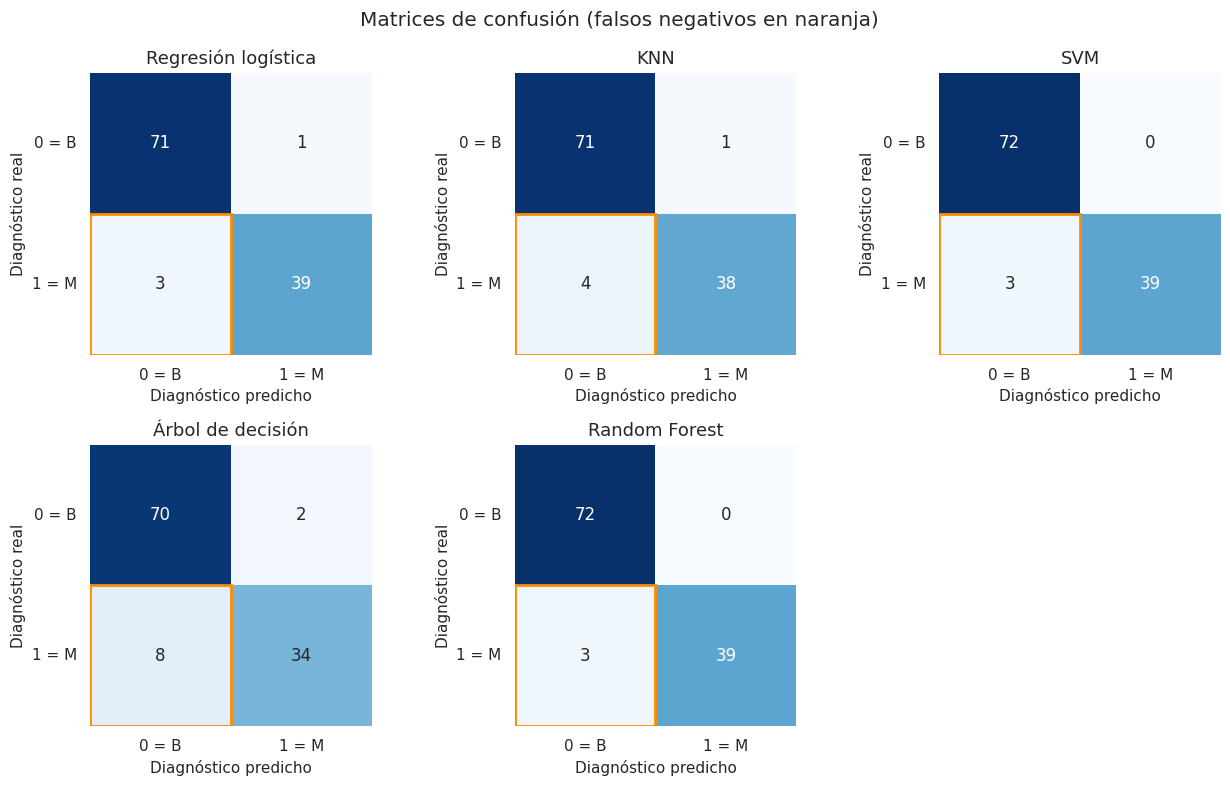

,Modelo,Falsos_negativos_M
0,Regresión logística,3
1,SVM,3
2,Random Forest,3
3,KNN,4
4,Árbol de decisión,8


Cada falso negativo es un caso maligno (1 = M) clasificado como benigno (0 = B). Un conteo mayor indica que el modelo dejó sin detectar más casos malignos en este test.


In [19]:
from matplotlib.patches import Rectangle

matrices_confusion = {
    nombre_modelo: confusion_matrix(y_test, y_pred_por_modelo[nombre_modelo], labels=[0, 1])
    for nombre_modelo in NOMBRES_MODELOS
}
maximo_matriz = max(matriz.max() for matriz in matrices_confusion.values())

fig_confusion, ejes_confusion = plt.subplots(2, 3, figsize=(13, 8))
etiquetas_diagnostico = ["0 = B", "1 = M"]
filas_falsos_negativos = []

for eje, (nombre_modelo, matriz) in zip(ejes_confusion.flat, matrices_confusion.items()):
    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        vmin=0,
        vmax=maximo_matriz,
        cbar=False,
        square=True,
        xticklabels=etiquetas_diagnostico,
        yticklabels=etiquetas_diagnostico,
        ax=eje,
    )
    eje.set(title=nombre_modelo, xlabel="Diagnóstico predicho", ylabel="Diagnóstico real")
    eje.tick_params(axis="y", labelrotation=0)
    # La fila 1 y la columna 0 contienen los falsos negativos de malignidad.
    eje.add_patch(Rectangle((0, 1), 1, 1, fill=False, edgecolor="darkorange", linewidth=2))
    filas_falsos_negativos.append({
        "Modelo": nombre_modelo,
        "Falsos_negativos_M": int(matriz[1, 0]),
    })

ejes_confusion.flat[-1].set_visible(False)
fig_confusion.suptitle("Matrices de confusión (falsos negativos en naranja)")
fig_confusion.tight_layout()
plt.show()

resumen_falsos_negativos = (
    pd.DataFrame(filas_falsos_negativos)
    .sort_values("Falsos_negativos_M", kind="stable")
    .reset_index(drop=True)
)
display(resumen_falsos_negativos)
print(
    "Cada falso negativo es un caso maligno (1 = M) clasificado como benigno (0 = B). "
    "Un conteo mayor indica que el modelo dejó sin detectar más casos malignos en este test."
)

### 5.4. Curvas ROC comparadas

**Responsable: Aldana.**

**Qué debes hacer**

- Utiliza las puntuaciones registradas en `y_score_por_modelo` y las etiquetas verdaderas `y_test` para construir una curva ROC por clasificador.
- Incluye la diagonal de azar, leyenda legible y el AUC de cada modelo. Si es viable, unifica las cinco curvas en un mismo gráfico para comparar.
- Explica en pocas líneas que ROC-AUC evalúa discriminación a varios umbrales y que no reemplaza el análisis de Recall_M ni falsos negativos.

**Resultado esperado / criterio de aceptación**

Figura ROC reproducible de los cinco modelos y explicación coherente de sus AUC.

**Atención:** No usar `y_pred` binario como entrada a `roc_curve` cuando existen scores/probabilidades.

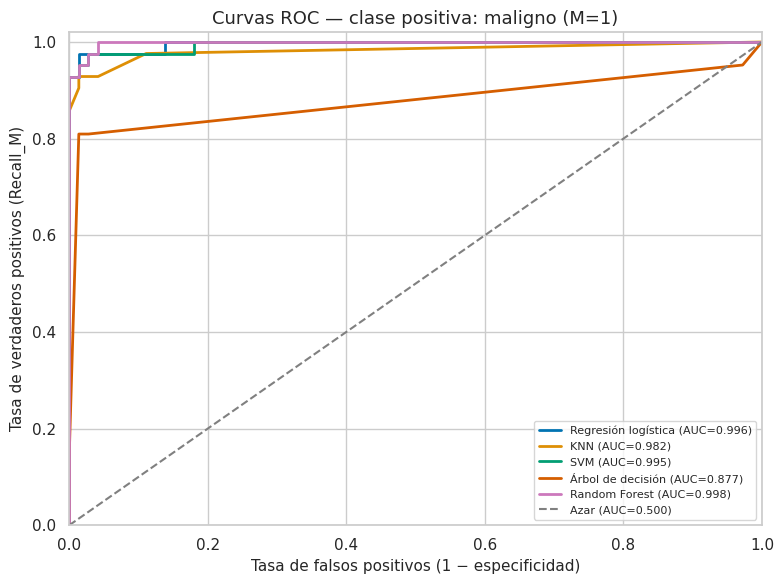

,Modelo,ROC_AUC
0,Regresión logística,0.9960
1,KNN,0.9825
2,SVM,0.9947
3,Árbol de decisión,0.8770
4,Random Forest,0.9980


**Interpretación:** la tabla y la leyenda muestran el AUC observado de los cinco modelos sobre el mismo test. ROC-AUC resume discriminación a través de varios umbrales; 0.5 representa discriminación al azar y 1 separación perfecta en esta muestra. No mide calibración ni reemplaza Recall_M y falsos negativos del umbral utilizado en 5.1/5.3. No se selecciona un umbral ni se reajustan hiperparámetros con estas curvas; diferencias pequeñas requieren validación adicional.

In [20]:
# 5.4 — cinco curvas ROC desde los scores comunes de 5.1.
_requeridas_roc = ("y_score_por_modelo", "y_test", "NOMBRES_MODELOS")
_faltantes_roc = [nombre for nombre in _requeridas_roc if nombre not in globals()]
if _faltantes_roc:
    raise RuntimeError("Ejecuta 5.1 antes de 5.4. Faltan: " + ", ".join(_faltantes_roc))
_y_roc = np.asarray(y_test)
if _y_roc.ndim != 1 or set(np.unique(_y_roc)) != {0, 1}:
    raise ValueError("y_test debe ser un vector con ambas clases, 1=M y 0=B.")
_faltan_scores_roc = set(NOMBRES_MODELOS) - set(y_score_por_modelo)
if _faltan_scores_roc:
    raise ValueError(f"Faltan puntuaciones para las cinco curvas: {sorted(_faltan_scores_roc)}")

curvas_roc = {}
_filas_auc = []
fig, ax = plt.subplots(figsize=(8, 6))
for nombre, color in zip(NOMBRES_MODELOS, sns.color_palette("colorblind", len(NOMBRES_MODELOS))):
    # Son probabilidades de M o decision_function orientada a M por 5.1.
    # No se usa y_pred binario ni se vuelve a ajustar ningún estimador.
    score = y_score_por_modelo[nombre]
    if isinstance(score, pd.Series) and not score.index.equals(y_test.index):
        raise ValueError(f"{nombre}: índices de los scores desalineados con y_test.")
    score = np.asarray(score, dtype=float)
    if score.ndim != 1 or len(score) != len(_y_roc) or not np.isfinite(score).all():
        raise ValueError(f"{nombre}: se requiere un score finito por muestra de test.")
    fpr, tpr, umbrales = roc_curve(_y_roc, score, pos_label=1)
    auc_observado = float(roc_auc_score(_y_roc, score))
    curvas_roc[nombre] = {"fpr": fpr, "tpr": tpr, "umbrales": umbrales, "auc": auc_observado}
    _filas_auc.append({"Modelo": nombre, "ROC_AUC": auc_observado})
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{nombre} (AUC={auc_observado:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC=0.500)")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Tasa de falsos positivos (1 − especificidad)",
       ylabel="Tasa de verdaderos positivos (Recall_M)", title="Curvas ROC — clase positiva: maligno (M=1)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
auc_roc = pd.DataFrame(_filas_auc)
display(auc_roc.round(4))
display(Markdown(
    "**Interpretación:** la tabla y la leyenda muestran el AUC observado de "
    "los cinco modelos sobre el mismo test. ROC-AUC resume discriminación a través "
    "de varios umbrales; 0.5 representa discriminación al azar y 1 separación perfecta "
    "en esta muestra. No mide calibración ni reemplaza Recall_M y falsos negativos "
    "del umbral utilizado en 5.1/5.3. No se selecciona un umbral ni se reajustan "
    "hiperparámetros con estas curvas; diferencias pequeñas requieren validación adicional."))


### 5.5. Análisis de errores y elección del modelo

**Responsable: Marco.**

**Qué debes hacer**

- Cruza la tabla de métricas con las matrices de confusión: identifica cuál(es) detectan más casos M y cuál(es) generan menos falsos negativos.
- Propón un modelo preferido **para el ejercicio académico**, justificando el equilibrio entre Recall_M, Precision_M, F1_M y ROC_AUC y aclarando las limitaciones del conjunto de prueba pequeño.
- Explica por qué seleccionar según Accuracy exclusivamente puede ser inapropiado si la prioridad son las muestras malignas.
- No afirmar que el mejor modelo sirve para uso clínico real ni ajustar umbrales sobre el test para reportar el mismo test como validación imparcial.

**Resultado esperado / criterio de aceptación**

Selección argumentada y basada en resultados reales, sin sobreinterpretar el rendimiento.

In [21]:
# Comparación académica basada en los resultados observados. Vera conserva la autoría
# y presentación de las matrices de confusión de 5.3.
requeridas_55 = ("resultados_df", "y_pred_por_modelo", "y_test")
faltantes_55 = [nombre for nombre in requeridas_55 if nombre not in globals()]
if faltantes_55:
    print("PENDIENTE: ejecutar 5.1 y disponer de y_test. Faltan: " + ", ".join(faltantes_55))
else:
    columnas_55 = {"Modelo", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"}
    if not columnas_55.issubset(resultados_df.columns):
        raise ValueError("resultados_df no contiene todas las métricas requeridas para 5.5.")
    if set(resultados_df["Modelo"].tolist()) != set(NOMBRES_MODELOS):
        raise ValueError("resultados_df debe incluir exactamente los cinco clasificadores acordados.")
    faltan_preds_55 = [n for n in NOMBRES_MODELOS if n not in y_pred_por_modelo]
    if faltan_preds_55:
        raise ValueError("Faltan predicciones de: " + ", ".join(faltan_preds_55))
    y_real = np.asarray(y_test).ravel()
    if not set(np.unique(y_real).tolist()).issubset({0, 1}) or set(np.unique(y_real)) != {0, 1}:
        raise ValueError("y_test debe codificar ambas clases: 0=B y 1=M.")
    conteo_fn = {}
    for nombre in NOMBRES_MODELOS:
        pred = np.asarray(y_pred_por_modelo[nombre]).ravel()
        if len(pred) != len(y_real):
            raise ValueError(f"{nombre}: predicciones y y_test tienen dimensiones distintas.")
        if not set(np.unique(pred).tolist()).issubset({0, 1}):
            raise ValueError(f"{nombre}: predicciones fuera de la codificación 0=B, 1=M.")
        conteo_fn[nombre] = int(np.sum((y_real == 1) & (pred == 0)))
    analisis_df = resultados_df.copy()
    analisis_df["Falsos_negativos_M"] = analisis_df["Modelo"].map(conteo_fn)
    if analisis_df["Falsos_negativos_M"].isna().any():
        raise ValueError("No fue posible asociar todos los conteos de falsos negativos a los modelos.")
    display(analisis_df.sort_values(
        ["Recall_M", "F1_M", "ROC_AUC"], ascending=[False, False, False], kind="stable"
    ).reset_index(drop=True).round(4))
    max_recall = analisis_df["Recall_M"].max()
    max_precision = analisis_df["Precision_M"].max()
    max_f1 = analisis_df["F1_M"].max()
    max_auc = analisis_df["ROC_AUC"].max()
    min_fn = int(analisis_df["Falsos_negativos_M"].min())
    print("Mayor Recall_M (más detección de malignidad): " + ", ".join(
        analisis_df.loc[analisis_df["Recall_M"] == max_recall, "Modelo"].tolist()))
    print("Menor cantidad de falsos negativos M: " + ", ".join(
        analisis_df.loc[analisis_df["Falsos_negativos_M"] == min_fn, "Modelo"].tolist()) + f" ({min_fn})")
    print("Mayor Precision_M: " + ", ".join(analisis_df.loc[analisis_df["Precision_M"] == max_precision, "Modelo"].tolist()))
    print("Mayor F1_M: " + ", ".join(analisis_df.loc[analisis_df["F1_M"] == max_f1, "Modelo"].tolist()))
    print("Mayor ROC_AUC: " + ", ".join(analisis_df.loc[analisis_df["ROC_AUC"] == max_auc, "Modelo"].tolist()))
    # Regla declarada: minimizar FN; desempates por Recall_M, F1_M y ROC_AUC.
    analisis_df = analisis_df.sort_values(
        ["Falsos_negativos_M", "Recall_M", "F1_M", "ROC_AUC"],
        ascending=[True, False, False, False], kind="stable"
    ).reset_index(drop=True)
    recomendado = analisis_df.iloc[0]
    print(f"Criterio académico: mínimo FN, luego máximo Recall_M, F1_M y ROC_AUC. "
          f"Recomendación para este test: {recomendado['Modelo']}.")
    print("Accuracy no debe ser el único criterio cuando interesa detectar malignidad: puede ocultar falsos negativos. "
          "Precision_M, Recall_M, F1_M, ROC_AUC y FN representan aspectos distintos. "
          "La recomendación describe esta partición académica y no implica utilidad clínica ni superioridad general.")

,Modelo,Accuracy,Precision_M,Recall_M,F1_M,ROC_AUC,Falsos_negativos_M
0,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9980,3
1,SVM,0.9737,1.0000,0.9286,0.9630,0.9947,3
2,Regresión logística,0.9649,0.9750,0.9286,0.9512,0.9960,3
3,KNN,0.9561,0.9744,0.9048,0.9383,0.9825,4
4,Árbol de decisión,0.9123,0.9444,0.8095,0.8718,0.8770,8


Mayor Recall_M (más detección de malignidad): Regresión logística, SVM, Random Forest
Menor cantidad de falsos negativos M: Regresión logística, SVM, Random Forest (3)
Mayor Precision_M: SVM, Random Forest
Mayor F1_M: SVM, Random Forest
Mayor ROC_AUC: Random Forest
Criterio académico: mínimo FN, luego máximo Recall_M, F1_M y ROC_AUC. Recomendación para este test: Random Forest.
Accuracy no debe ser el único criterio cuando interesa detectar malignidad: puede ocultar falsos negativos. Precision_M, Recall_M, F1_M, ROC_AUC y FN representan aspectos distintos. La recomendación describe esta partición académica y no implica utilidad clínica ni superioridad general.


## 6. Interpretación y discusión

### 6.1. Importancia de características en Random Forest

**Responsable: Vera.**

**Qué debes hacer**

- Recupera `feature_importances_` del modelo `Random Forest` entrenado en 4.5 y vincúlalo con los nombres originales de `X.columns`.
- Muestra una gráfica horizontal con las 10 características de mayor importancia.
- Explica que las importancias internas del bosque indican contribución al modelo, **no causalidad** ni relevancia médica validada.

**Resultado esperado / criterio de aceptación**

Gráfico legible de top 10 de características y explicación breve de sus limitaciones.

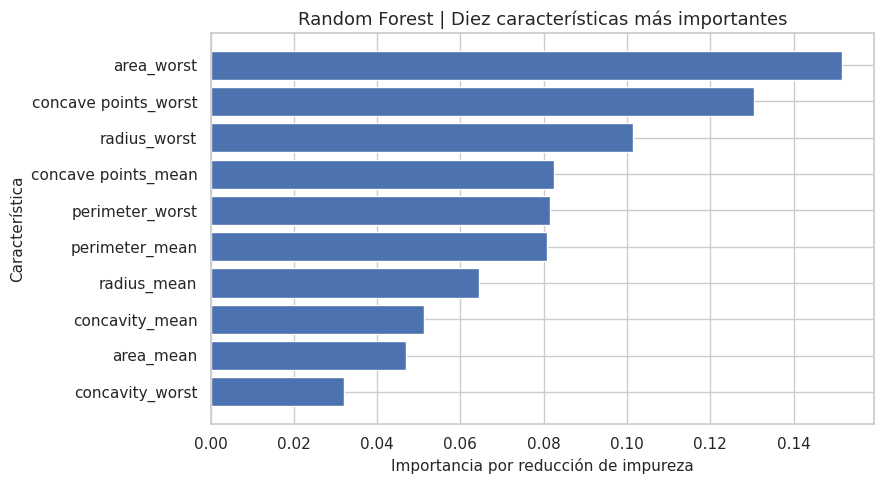

Las importancias resumen cuánto contribuyó cada característica a reducir la impureza en el bosque entrenado. Las conclusiones causales o clínicas requieren evidencia independiente.


In [22]:
bosque_entrenado = modelos_entrenados["Random Forest"]
importancias_bosque = bosque_entrenado.feature_importances_

if (
    not X.columns.equals(pd.Index(bosque_entrenado.feature_names_in_))
    or len(importancias_bosque) != len(X.columns)
):
    raise ValueError("Las importancias del bosque deben corresponder a las columnas de X, en el mismo orden.")

importancias_principales = (
    pd.Series(importancias_bosque, index=X.columns)
    .nlargest(10)
    .sort_values(ascending=True, kind="stable")
)
fig_importancias, eje_importancias = plt.subplots(figsize=(9, 5))
eje_importancias.barh(importancias_principales.index, importancias_principales.values)
eje_importancias.set(
    title="Random Forest | Diez características más importantes",
    xlabel="Importancia por reducción de impureza",
    ylabel="Característica",
)
fig_importancias.tight_layout()
plt.show()

print(
    "Las importancias resumen cuánto contribuyó cada característica a reducir la impureza "
    "en el bosque entrenado. Las conclusiones causales o clínicas requieren evidencia independiente."
)

### 6.2. Síntesis del EDA frente a los resultados

**Responsable: Aldana.**

**Qué debes hacer**

- Relaciona dos o tres hallazgos del EDA (balance, distribuciones o correlaciones) con lo observado en el rendimiento de los modelos.
- Distingue hechos observados de interpretaciones; evita afirmar que cierta variable causa malignidad.
- Enumera limitaciones metodológicas: tamaño del dataset, variabilidad de una partición train/test y ausencia de validación externa.

**Resultado esperado / criterio de aceptación**

Párrafo o lista breve de hallazgos y limitaciones respaldados por las salidas del notebook.

In [23]:
# 6.2 — Síntesis dinámica del EDA y de los resultados de distintas familias.
_requeridas_sintesis = ("resumen_clases_eda", "medianas_por_diagnostico_eda", "pares_correlacion_eda")
_faltantes_sintesis = [nombre for nombre in _requeridas_sintesis if nombre not in globals()]
if _faltantes_sintesis:
    raise RuntimeError("Completa primero 2.1–2.3. Faltan: " + ", ".join(_faltantes_sintesis))

_par_principal_eda = pares_correlacion_eda.iloc[0]
_medianas_tamano_eda = "; ".join(
    f"{columna}: B={medianas_por_diagnostico_eda.loc[0, columna]:.4g}, "
    f"M={medianas_por_diagnostico_eda.loc[1, columna]:.4g}"
    for columna in variables_eda[:2]
)
_texto_sintesis_eda = [
    f"**Balance observado:** {100*proporcion_maligna_eda:.1f}% de muestras malignas. "
    f"La Accuracy de una predicción mayoritaria constante sería {accuracy_mayoritaria_eda:.3f}; "
    "este referente explica por qué la comparación también debe examinar Recall_M y FN.",
    f"**Distribuciones observadas:** medianas de tamaño, {_medianas_tamano_eda}. "
    "Estas diferencias describen asociaciones con el diagnóstico y motivan estudiar "
    "capacidad de discriminación; no prueban causalidad ni separación completa. "
    "Las diferencias de escala justifican el preprocesamiento de regresión logística, "
    "KNN y SVM; los árboles deciden mediante umbrales sobre cada característica.",
    f"**Correlación observada:** {_par_principal_eda['variable_1']} y "
    f"{_par_principal_eda['variable_2']} presentan r={_par_principal_eda['correlacion']:.3f}. "
    "La información compartida limita interpretar coeficientes como contribuciones "
    "independientes y también puede repartir la importancia entre predictores en árboles. "
    "La regularización de la regresión logística estabiliza el ajuste; "
    "el EDA no ha eliminado predictores ni optimizado hiperparámetros.",
]

# Consumir las métricas ya publicadas por 5.1, sin predecir ni reajustar modelos.
_metricas_sintesis = ["Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"]
_familias_sintesis = {
    "Regresión logística": "modelo lineal probabilístico",
    "KNN": "vecinos y distancias",
    "SVM": "máquina de margen",
    "Árbol de decisión": "árbol individual",
    "Random Forest": "ensamble de árboles",
}
if "resultados_df" not in globals():
    _texto_sintesis_eda.append(
        "**Rendimiento pendiente:** completar la evaluación centralizada de 5.1 antes de "
        "vincular cifras de rendimiento con los hallazgos; no se presuponen resultados.")
else:
    _columnas_sintesis = {"Modelo", *_metricas_sintesis}
    if not isinstance(resultados_df, pd.DataFrame) or not _columnas_sintesis.issubset(resultados_df.columns):
        raise ValueError("resultados_df debe conservar el esquema de métricas de 5.1.")
    # Toda anotación se hace en una copia local, preservando la tabla central.
    _tabla_sintesis = resultados_df[["Modelo", *_metricas_sintesis]].copy(deep=True)
    if _tabla_sintesis["Modelo"].duplicated().any():
        raise ValueError("Se requiere una fila de métricas por clasificador.")
    if not _tabla_sintesis["Modelo"].isin(_familias_sintesis).all():
        raise ValueError("La tabla contiene nombres ajenos a los cinco clasificadores acordados.")
    _valores_sintesis = _tabla_sintesis[_metricas_sintesis].apply(pd.to_numeric, errors="raise")
    if (not np.isfinite(_valores_sintesis.to_numpy(dtype=float)).all()
            or not _valores_sintesis.ge(0).all().all()
            or not _valores_sintesis.le(1).all().all()):
        raise ValueError("Las métricas observadas deben ser finitas y pertenecer a [0, 1].")
    _tabla_sintesis[_metricas_sintesis] = _valores_sintesis
    _tabla_sintesis["Familia"] = _tabla_sintesis["Modelo"].map(_familias_sintesis)
    display(_tabla_sintesis[["Modelo", "Familia", *_metricas_sintesis]].round(4))
    for _fila_sintesis in _tabla_sintesis.itertuples(index=False):
        _texto_sintesis_eda.append(
            f"**{_fila_sintesis.Modelo} ({_fila_sintesis.Familia}):** "
            f"Accuracy={_fila_sintesis.Accuracy:.3f}, Precision_M={_fila_sintesis.Precision_M:.3f}, "
            f"Recall_M={_fila_sintesis.Recall_M:.3f}, F1_M={_fila_sintesis.F1_M:.3f} "
            f"y ROC-AUC={_fila_sintesis.ROC_AUC:.3f}.")

    # Comparar familias distintas con pares fijados antes de observar las cifras.
    # Se priorizan la frontera lineal frente al ensamble y las distancias frente
    # al árbol individual. Con resultados parciales se usa el primer par disponible.
    _por_modelo_sintesis = _tabla_sintesis.set_index("Modelo")
    _pares_sintesis = [
        ("Regresión logística", "Random Forest"),
        ("KNN", "Árbol de decisión"),
        ("SVM", "Random Forest"),
    ]
    _pares_disponibles_sintesis = [
        (primero, segundo) for primero, segundo in _pares_sintesis
        if primero in _por_modelo_sintesis.index and segundo in _por_modelo_sintesis.index
    ]
    if not _pares_disponibles_sintesis:
        _nombres_sintesis = [nombre for nombre in _familias_sintesis if nombre in _por_modelo_sintesis.index]
        _pares_disponibles_sintesis = [
            (primero, segundo)
            for i, primero in enumerate(_nombres_sintesis)
            for segundo in _nombres_sintesis[i + 1:]
            if _familias_sintesis[primero] != _familias_sintesis[segundo]
        ][:1]
    for _primero_sintesis, _segundo_sintesis in _pares_disponibles_sintesis:
        _diferencias_sintesis = (
            _por_modelo_sintesis.loc[_primero_sintesis, _metricas_sintesis]
            - _por_modelo_sintesis.loc[_segundo_sintesis, _metricas_sintesis]
        )
        _texto_diferencias_sintesis = ", ".join(
            f"Δ{metrica}={_diferencias_sintesis[metrica]:+.3f}" for metrica in _metricas_sintesis
        )
        _texto_sintesis_eda.append(
            f"**Comparación {_primero_sintesis} frente a {_segundo_sintesis}:** "
            f"{_texto_diferencias_sintesis}. Cada delta corresponde al primer modelo menos "
            "el segundo; un valor positivo indica una métrica mayor y cero indica igualdad "
            "al redondeo mostrado. AUC compara discriminación a distintos umbrales; "
            "Recall_M contrasta detección de malignos, Precision_M el acierto de las alertas "
            "y F1_M su equilibrio. Las cifras no demuestran significancia estadística.")
    _faltantes_modelos_sintesis = set(_familias_sintesis) - set(_por_modelo_sintesis.index)
    if _faltantes_modelos_sintesis:
        _texto_sintesis_eda.append(
            "**Comparación parcial:** faltan métricas de "
            + ", ".join(sorted(_faltantes_modelos_sintesis)) + ".")
    if not _pares_disponibles_sintesis:
        _texto_sintesis_eda.append(
            "**Comparación entre familias pendiente:** se requieren resultados observados "
            "de al menos dos clasificadores de familias diferentes.")
    _texto_sintesis_eda.append(
        "**Relación con el EDA:** las diferencias entre distribuciones se contrastan con "
        "el ROC-AUC de cada familia para describir su discriminación en el mismo test. "
        "El balance de clases motiva contrastar Accuracy con Recall_M, Precision_M y F1_M, "
        "sin asumir que una exactitud alta elimina los falsos negativos. La correlación "
        "entre predictores limita atribuir el rendimiento a una variable individual. "
        "Una diferencia entre modelos lineales, vecinos, margen y árboles no demuestra "
        "que el escalamiento o una característica aislada la haya causado.")

_texto_sintesis_eda.append(
    "**Validación interna implementada:** las secciones 4.2 y 4.3 incorporan "
    "validación cruzada de cinco pliegues para KNN y SVM exclusivamente sobre "
    "X_train_cv e y_train. Sus pipelines ajustan la imputación y el escalamiento "
    "dentro de cada pliegue. KNN selecciona el número de vecinos por F1 medio; "
    "SVM evalúa una configuración fija mediante F1 medio. Estas validaciones "
    "internas complementan la comparación final de 5.1 sobre el test reservado.")
_texto_sintesis_eda.append(
    f"**Limitaciones:** {len(X)} muestras, una sola partición final entrenamiento/prueba, "
    "EDA descriptivo que incluye las futuras filas de test y ausencia de validación externa. "
    "Este EDA no se usa para seleccionar variables, modelos o umbrales. La interpretación "
    "comparativa del test es académica; no demuestra desempeño clínico ni generalización. "
    "Quedan como recomendaciones futuras una validación cruzada homogénea de los cinco "
    "clasificadores dentro de entrenamiento, con los mismos pliegues y métricas, "
    "y una validación externa con datos independientes.")
conclusion_eda = "\n\n".join(_texto_sintesis_eda)
display(Markdown(conclusion_eda))


,Modelo,Familia,Accuracy,Precision_M,Recall_M,F1_M,ROC_AUC
0,Regresión logística,modelo lineal probabilístico,0.9649,0.9750,0.9286,0.9512,0.9960
1,KNN,vecinos y distancias,0.9561,0.9744,0.9048,0.9383,0.9825
2,SVM,máquina de margen,0.9737,1.0000,0.9286,0.9630,0.9947
3,Árbol de decisión,árbol individual,0.9123,0.9444,0.8095,0.8718,0.8770
4,Random Forest,ensamble de árboles,0.9737,1.0000,0.9286,0.9630,0.9980


**Balance observado:** 37.3% de muestras malignas. La Accuracy de una predicción mayoritaria constante sería 0.627; este referente explica por qué la comparación también debe examinar Recall_M y FN.

**Distribuciones observadas:** medianas de tamaño, radius_mean: B=12.2, M=17.33; area_mean: B=458.4, M=932. Estas diferencias describen asociaciones con el diagnóstico y motivan estudiar capacidad de discriminación; no prueban causalidad ni separación completa. Las diferencias de escala justifican el preprocesamiento de regresión logística, KNN y SVM; los árboles deciden mediante umbrales sobre cada característica.

**Correlación observada:** radius_mean y perimeter_mean presentan r=0.998. La información compartida limita interpretar coeficientes como contribuciones independientes y también puede repartir la importancia entre predictores en árboles. La regularización de la regresión logística estabiliza el ajuste; el EDA no ha eliminado predictores ni optimizado hiperparámetros.

**Regresión logística (modelo lineal probabilístico):** Accuracy=0.965, Precision_M=0.975, Recall_M=0.929, F1_M=0.951 y ROC-AUC=0.996.

**KNN (vecinos y distancias):** Accuracy=0.956, Precision_M=0.974, Recall_M=0.905, F1_M=0.938 y ROC-AUC=0.982.

**SVM (máquina de margen):** Accuracy=0.974, Precision_M=1.000, Recall_M=0.929, F1_M=0.963 y ROC-AUC=0.995.

**Árbol de decisión (árbol individual):** Accuracy=0.912, Precision_M=0.944, Recall_M=0.810, F1_M=0.872 y ROC-AUC=0.877.

**Random Forest (ensamble de árboles):** Accuracy=0.974, Precision_M=1.000, Recall_M=0.929, F1_M=0.963 y ROC-AUC=0.998.

**Comparación Regresión logística frente a Random Forest:** ΔAccuracy=-0.009, ΔPrecision_M=-0.025, ΔRecall_M=+0.000, ΔF1_M=-0.012, ΔROC_AUC=-0.002. Cada delta corresponde al primer modelo menos el segundo; un valor positivo indica una métrica mayor y cero indica igualdad al redondeo mostrado. AUC compara discriminación a distintos umbrales; Recall_M contrasta detección de malignos, Precision_M el acierto de las alertas y F1_M su equilibrio. Las cifras no demuestran significancia estadística.

**Comparación KNN frente a Árbol de decisión:** ΔAccuracy=+0.044, ΔPrecision_M=+0.030, ΔRecall_M=+0.095, ΔF1_M=+0.066, ΔROC_AUC=+0.105. Cada delta corresponde al primer modelo menos el segundo; un valor positivo indica una métrica mayor y cero indica igualdad al redondeo mostrado. AUC compara discriminación a distintos umbrales; Recall_M contrasta detección de malignos, Precision_M el acierto de las alertas y F1_M su equilibrio. Las cifras no demuestran significancia estadística.

**Comparación SVM frente a Random Forest:** ΔAccuracy=+0.000, ΔPrecision_M=+0.000, ΔRecall_M=+0.000, ΔF1_M=+0.000, ΔROC_AUC=-0.003. Cada delta corresponde al primer modelo menos el segundo; un valor positivo indica una métrica mayor y cero indica igualdad al redondeo mostrado. AUC compara discriminación a distintos umbrales; Recall_M contrasta detección de malignos, Precision_M el acierto de las alertas y F1_M su equilibrio. Las cifras no demuestran significancia estadística.

**Relación con el EDA:** las diferencias entre distribuciones se contrastan con el ROC-AUC de cada familia para describir su discriminación en el mismo test. El balance de clases motiva contrastar Accuracy con Recall_M, Precision_M y F1_M, sin asumir que una exactitud alta elimina los falsos negativos. La correlación entre predictores limita atribuir el rendimiento a una variable individual. Una diferencia entre modelos lineales, vecinos, margen y árboles no demuestra que el escalamiento o una característica aislada la haya causado.

**Validación interna implementada:** las secciones 4.2 y 4.3 incorporan validación cruzada de cinco pliegues para KNN y SVM exclusivamente sobre X_train_cv e y_train. Sus pipelines ajustan la imputación y el escalamiento dentro de cada pliegue. KNN selecciona el número de vecinos por F1 medio; SVM evalúa una configuración fija mediante F1 medio. Estas validaciones internas complementan la comparación final de 5.1 sobre el test reservado.

**Limitaciones:** 569 muestras, una sola partición final entrenamiento/prueba, EDA descriptivo que incluye las futuras filas de test y ausencia de validación externa. Este EDA no se usa para seleccionar variables, modelos o umbrales. La interpretación comparativa del test es académica; no demuestra desempeño clínico ni generalización. Quedan como recomendaciones futuras una validación cruzada homogénea de los cinco clasificadores dentro de entrenamiento, con los mismos pliegues y métricas, y una validación externa con datos independientes.

### 6.3. Conclusiones, reproducibilidad y recomendaciones

**Responsable: Marco.**

**Responsable: Marco — Síntesis basada en los resultados realmente observados.**

- Resume el método train/test, la escala ajustada solo con entrenamiento y los cinco modelos.
- Fundamenta la recomendación en los valores reales de `resultados_df` y los falsos negativos de `analisis_df`, sin inventar métricas.
- **Distingue validaciones realizadas de trabajo futuro:** KNN selecciona `k` mediante CV de cinco pliegues; SVM evalúa una configuración fija mediante CV de cinco pliegues, ambas con preprocesamiento dentro de cada pliegue. Queda pendiente una CV homogénea para los cinco modelos y validación externa.
- Verifica coherencia entre títulos, figuras, leyendas y conclusiones.

**Resultado esperado:** conclusiones dinámicas coherentes con las evidencias, sin afirmar utilidad clínica.


In [24]:
from IPython.display import display, Markdown

nombres_esperados = list(NOMBRES_MODELOS)
metricas_esperadas = ["Modelo", "Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"]
conclusiones_generadas = False
conclusion_modelo_recomendado = None
conclusion_metricas_resumen = None

if "resultados_df" not in globals() or "analisis_df" not in globals():
    display(Markdown("""### Conclusiones (pendientes de integración)

El objetivo es comparar regresión logística, KNN, SVM, árbol de decisión y Random Forest en la clasificación binaria del conjunto Breast Cancer Wisconsin (Diagnostic), con 1 = maligno y 0 = benigno. La metodología acordada contempla una partición estratificada de entrenamiento y prueba; el escalador se ajusta únicamente con entrenamiento y los modelos se comparan sobre el mismo conjunto de prueba.

**PENDIENTE:** aún no están disponibles las métricas y el análisis comparativo completos. No se atribuye rendimiento a ningún clasificador ni se muestran valores hasta integrar los cinco modelos reales.

La interpretación final estará limitada por el tamaño del conjunto de prueba y por una única partición. KNN seleccionó k mediante validación cruzada de cinco pliegues, y SVM evaluó una configuración fija del mismo modo, con imputación y escalamiento dentro de cada pliegue. Quedan como trabajo futuro una comparación mediante validación cruzada homogénea de los cinco clasificadores y la validación externa con datos independientes.

Este experimento es académico y no constituye validación clínica."""))
else:
    if not set(metricas_esperadas).issubset(resultados_df.columns):
        raise ValueError("resultados_df no tiene el esquema requerido para redactar conclusiones.")
    if set(resultados_df["Modelo"].tolist()) != set(nombres_esperados):
        raise ValueError("Las conclusiones requieren resultados de los cinco modelos, exactamente una fila por modelo.")
    if "Falsos_negativos_M" not in analisis_df.columns or set(analisis_df["Modelo"]) != set(nombres_esperados):
        raise ValueError("Ejecute 5.5 y verifique los falsos negativos de los cinco modelos antes de concluir.")
    if analisis_df["Modelo"].duplicated().any() or resultados_df["Modelo"].duplicated().any():
        raise ValueError("Se esperaba una sola fila por clasificador en resultados y análisis.")
    fila = analisis_df.sort_values(
        ["Falsos_negativos_M", "Recall_M", "F1_M", "ROC_AUC"],
        ascending=[True, False, False, False], kind="stable"
    ).iloc[0]
    conclusion_modelo_recomendado = fila["Modelo"]
    conclusion_metricas_resumen = fila[["Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC", "Falsos_negativos_M"]].to_dict()
    conclusiones_generadas = True
    resultados = resultados_df.set_index("Modelo").loc[nombres_esperados]
    lineas = [
        "### Conclusiones, reproducibilidad y recomendaciones", "",
        "El objetivo fue comparar cinco clasificadores supervisados para distinguir muestras benignas (0) y malignas (1). La metodología utilizó una partición estratificada entrenamiento/prueba y reservó el ajuste del escalador para entrenamiento. Regresión logística, KNN y SVM reciben datos escalados; árbol de decisión y Random Forest reciben predictores originales. Los cinco se evalúan sobre el mismo conjunto de prueba.", "",
        f"Con el criterio académico declarado (mínimo de falsos negativos y desempate por Recall_M, F1_M y ROC_AUC), la recomendación para esta partición es **{fila['Modelo']}**: Precision_M={fila['Precision_M']:.3f}, Recall_M={fila['Recall_M']:.3f}, F1_M={fila['F1_M']:.3f}, ROC_AUC={fila['ROC_AUC']:.3f} y falsos negativos={int(fila['Falsos_negativos_M'])}.", "",
        "Métricas observadas (sin redondeo previo al cálculo):", "",
        "| Modelo | Accuracy | Precision_M | Recall_M | F1_M | ROC_AUC |", "|---|---:|---:|---:|---:|---:|"
    ]
    for nombre, metrica in resultados.iterrows():
        lineas.append(f"| {nombre} | {metrica['Accuracy']:.3f} | {metrica['Precision_M']:.3f} | {metrica['Recall_M']:.3f} | {metrica['F1_M']:.3f} | {metrica['ROC_AUC']:.3f} |")
    lineas += ["", "Las cifras describen esta partición y pueden variar con otra muestra o partición; un test acotado no demuestra generalización ni utilidad clínica.", "", "**Validación cruzada realizada:** KNN seleccionó k mediante cinco pliegues y SVM evaluó una configuración fija con cinco pliegues. "
              "Ambos usaron pipelines que ajustan imputación y escalamiento dentro de cada pliegue de entrenamiento; no se utilizó test para esa selección.", "",
              "**Trabajo futuro recomendado:** comparación homogénea de los cinco clasificadores mediante los mismos pliegues y métricas, "
              "ajuste sistemático adicional de hiperparámetros solo en entrenamiento y validación externa con datos independientes."]
    display(Markdown("\n".join(lineas)))

### Conclusiones, reproducibilidad y recomendaciones

El objetivo fue comparar cinco clasificadores supervisados para distinguir muestras benignas (0) y malignas (1). La metodología utilizó una partición estratificada entrenamiento/prueba y reservó el ajuste del escalador para entrenamiento. Regresión logística, KNN y SVM reciben datos escalados; árbol de decisión y Random Forest reciben predictores originales. Los cinco se evalúan sobre el mismo conjunto de prueba.

Con el criterio académico declarado (mínimo de falsos negativos y desempate por Recall_M, F1_M y ROC_AUC), la recomendación para esta partición es **Random Forest**: Precision_M=1.000, Recall_M=0.929, F1_M=0.963, ROC_AUC=0.998 y falsos negativos=3.

Métricas observadas (sin redondeo previo al cálculo):

| Modelo | Accuracy | Precision_M | Recall_M | F1_M | ROC_AUC |
|---|---:|---:|---:|---:|---:|
| Regresión logística | 0.965 | 0.975 | 0.929 | 0.951 | 0.996 |
| KNN | 0.956 | 0.974 | 0.905 | 0.938 | 0.982 |
| SVM | 0.974 | 1.000 | 0.929 | 0.963 | 0.995 |
| Árbol de decisión | 0.912 | 0.944 | 0.810 | 0.872 | 0.877 |
| Random Forest | 0.974 | 1.000 | 0.929 | 0.963 | 0.998 |

Las cifras describen esta partición y pueden variar con otra muestra o partición; un test acotado no demuestra generalización ni utilidad clínica.

**Validación cruzada realizada:** KNN seleccionó k mediante cinco pliegues y SVM evaluó una configuración fija con cinco pliegues. Ambos usaron pipelines que ajustan imputación y escalamiento dentro de cada pliegue de entrenamiento; no se utilizó test para esa selección.

**Trabajo futuro recomendado:** comparación homogénea de los cinco clasificadores mediante los mismos pliegues y métricas, ajuste sistemático adicional de hiperparámetros solo en entrenamiento y validación externa con datos independientes.

## 7. Control final de integración

### 7.1. Verificación y entrega en Colab

**Responsable: Marco.**

**Qué debes hacer**

- Abre la versión final en Google Colab, usa **Reiniciar sesión y ejecutar todo** y comprueba que todas las celdas terminan sin excepción.
- Comprueba que en un entorno limpio se puede obtener `df_raw`, `X`, `y`, la división train/test, los cinco modelos, `resultados_df` y todas las figuras.
- Confirma que los resultados se han calculado con etiquetas 1=M y 0=B y que no hubo `fit` del escalador sobre test ni preprocesamiento con información del test.
- Revisa los nombres de responsables en celdas de texto, la ortografía, títulos, leyendas y que no haya salidas de errores ni celdas experimentales sobrantes.
- Registra de forma breve la fuente del dataset, las versiones principales de librerías si resulta útil, y el nombre del archivo final compartido con el grupo.

**Resultado esperado / criterio de aceptación**

Notebook listo para entregar: se ejecuta de arriba abajo en Colab y conserva evidencias de todas las etapas.

In [25]:
# Controles observables de integración. Ausencia de dependencias => PENDIENTE;
# una condición evaluada e incorrecta => FAIL.
def _reportar_estado(etiqueta, estado, detalle=""):
    if estado not in ("PASS", "FAIL", "PENDIENTE"):
        raise ValueError("Estado de verificación desconocido.")
    print(f"{estado}: {etiqueta}" + (f" — {detalle}" if detalle else ""))

compartidas = ["df_raw", "df_clean", "X", "y", "X_train", "X_test", "y_train", "y_test",
               "escalador", "X_train_scaled", "X_test_scaled"]
for nombre in compartidas:
    _reportar_estado(f"variable compartida {nombre}", "PASS" if nombre in globals() else "PENDIENTE",
                     "presente" if nombre in globals() else "aún no integrada")

if "sys" in globals():
    _reportar_estado("intérprete Python 3", "PASS" if sys.version_info.major == 3 else "FAIL",
                     sys.version.split()[0])
else:
    _reportar_estado("intérprete Python 3", "PENDIENTE", "no se pudo consultar sys.version_info")

if "RANDOM_STATE" in globals():
    _reportar_estado("RANDOM_STATE configurado en 42", "PASS" if RANDOM_STATE == 42 else "FAIL", str(RANDOM_STATE))
else:
    _reportar_estado("RANDOM_STATE configurado en 42", "PENDIENTE", "falta ejecutar 0.1")

if "modelos_entrenados" not in globals() or "tipo_entrada" not in globals():
    _reportar_estado("registro y tipos de los cinco modelos", "PENDIENTE", "faltan contenedores compartidos")
else:
    faltantes_modelos = [n for n in NOMBRES_MODELOS if n not in modelos_entrenados]
    faltantes_tipos = [n for n in NOMBRES_MODELOS if n not in tipo_entrada]
    extras_modelos = [n for n in modelos_entrenados if n not in NOMBRES_MODELOS]
    tipos_invalidos = {n: tipo_entrada[n] for n in tipo_entrada if n in NOMBRES_MODELOS and tipo_entrada[n] not in ("escalado", "original")}
    if extras_modelos or tipos_invalidos:
        _reportar_estado("registro y tipos de los cinco modelos", "FAIL", f"extras={extras_modelos}; tipos inválidos={tipos_invalidos}")
    elif faltantes_modelos or faltantes_tipos:
        _reportar_estado("registro y tipos de los cinco modelos", "PENDIENTE", f"faltan modelos={faltantes_modelos}; faltan tipos={faltantes_tipos}")
    else:
        _reportar_estado("registro y tipos de los cinco modelos", "PASS", "nombres exactos y valores de tipo válidos")

partes = ("X_train", "X_test", "y_train", "y_test", "X_train_scaled", "X_test_scaled")
if not all(nombre in globals() for nombre in partes):
    _reportar_estado("dimensiones train/test originales y escaladas", "PENDIENTE", "faltan particiones o matrices escaladas")
else:
    try:
        formas = {nombre: np.shape(globals()[nombre]) for nombre in partes}
        vectores = ("y_train", "y_test")
        matrices = ("X_train", "X_test", "X_train_scaled", "X_test_scaled")
        if any(len(formas[nombre]) != 1 for nombre in vectores):
            raise ValueError("y_train y y_test deben ser vectores unidimensionales")
        if any(len(formas[nombre]) != 2 for nombre in matrices):
            raise ValueError("las matrices X deben ser bidimensionales")
        dimensiones_ok = (
            formas["X_train"][0] == formas["y_train"][0]
            and formas["X_test"][0] == formas["y_test"][0]
            and formas["X_train"] == formas["X_train_scaled"]
            and formas["X_test"] == formas["X_test_scaled"]
            and formas["X_train"][1] == formas["X_test"][1]
        )
        _reportar_estado("dimensiones train/test originales y escaladas", "PASS" if dimensiones_ok else "FAIL",
                         f"formas={formas}")
    except Exception as error_forma:
        _reportar_estado("dimensiones train/test originales y escaladas", "FAIL",
                         f"dimensión inválida: {type(error_forma).__name__}: {error_forma}")

if "y" not in globals():
    _reportar_estado("codificación 1=M y 0=B", "PENDIENTE", "falta y")
else:
    valores_y = set(np.asarray(y).ravel().tolist())
    if not valores_y.issubset({0, 1}):
        _reportar_estado("codificación 1=M y 0=B", "FAIL", f"valores observados={valores_y}")
    elif "df_clean" not in globals() or "diagnosis" not in getattr(df_clean, "columns", []):
        _reportar_estado("significado semántico de las etiquetas", "PENDIENTE", "no hay diagnosis de referencia para comprobar M→1/B→0")
    else:
        diagnosis = df_clean["diagnosis"].astype(str).str.upper().to_numpy()
        etiquetas = np.asarray(y).ravel()
        semantica_ok = (len(diagnosis) == len(etiquetas) and
                        np.array_equal(etiquetas, np.where(diagnosis == "M", 1, np.where(diagnosis == "B", 0, -1))))
        _reportar_estado("codificación 1=M y 0=B contrastada con diagnosis", "PASS" if semantica_ok else "FAIL")

# Indicador parcial: la cantidad de filas vista por el escalador debe coincidir
# con train, pero esto no demuestra por sí sola sobre qué datos se llamó fit().
if "escalador" not in globals() or "X_train" not in globals():
    _reportar_estado("indicador parcial: n_samples_seen_ frente a filas de train", "PENDIENTE", "faltan escalador o X_train")
else:
    try:
        observadas = getattr(escalador, "n_samples_seen_", None)
        if observadas is None:
            _reportar_estado("indicador parcial: n_samples_seen_ frente a filas de train", "PENDIENTE", "el escalador no expone n_samples_seen_")
        else:
            coincide_train = bool(np.all(np.asarray(observadas) == len(X_train)))
            _reportar_estado("indicador parcial: n_samples_seen_ coincide con filas de train",
                             "PASS" if coincide_train else "FAIL",
                             "esta coincidencia no prueba que fit() usara exclusivamente train")
    except Exception as error_escalador:
        _reportar_estado("indicador parcial: n_samples_seen_ frente a filas de train", "FAIL",
                         f"no se pudo comprobar: {type(error_escalador).__name__}: {error_escalador}")

# Búsqueda limitada de llamadas directas; es evidencia parcial, no auditoría completa.
import re
historial_codigo = globals().get("In") or globals().get("_ih")
if historial_codigo is not None and len(historial_codigo) > 1:
    codigo_ejecutado = "\n".join(historial_codigo[1:-1])
    fit_directo_en_test = bool(re.search(r"\.fit(?:_transform)?\s*\(\s*X_test(?:_scaled)?\b", codigo_ejecutado))
    _reportar_estado("búsqueda parcial de llamadas directas fit(X_test)",
                     "FAIL" if fit_directo_en_test else "PASS",
                     "un resultado negativo no descarta otras formas de fuga")
else:
    _reportar_estado("búsqueda parcial de llamadas directas fit(X_test)", "PENDIENTE", "historial de código no disponible")

# La auditoría concluyente requiere revisar el flujo completo de carga, partición,
# transformaciones, selección y entrenamiento; estos indicadores no la sustituyen.
_reportar_estado("auditoría concluyente de ausencia de fuga de datos", "PENDIENTE",
                 "requiere revisar el flujo integrado y su ejecución desde sesión limpia")

if not all(nombre in globals() for nombre in ("resultados_df", "y_pred_por_modelo", "y_score_por_modelo", "y_test")):
    _reportar_estado("métricas, predicciones y scores ROC", "PENDIENTE", "falta ejecutar 5.1 con los cinco modelos")
else:
    esquema_ok = list(resultados_df.columns) == metricas_esperadas if "metricas_esperadas" in globals() else list(resultados_df.columns) == ["Modelo", "Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"]
    contenido_ok = (set(resultados_df["Modelo"]) == set(NOMBRES_MODELOS)
                    and all(n in y_pred_por_modelo and n in y_score_por_modelo for n in NOMBRES_MODELOS)
                    and all(len(y_pred_por_modelo[n]) == len(y_test) and len(y_score_por_modelo[n]) == len(y_test) for n in NOMBRES_MODELOS))
    if not esquema_ok or not contenido_ok:
        _reportar_estado("resultados y predicciones del conjunto de prueba", "FAIL", "esquema, modelos o longitudes inconsistentes")
    else:
        _reportar_estado("resultados y predicciones del conjunto de prueba", "PASS", "cinco modelos con longitudes compatibles")

if ("analisis_df" not in globals() or "Falsos_negativos_M" not in getattr(analisis_df, "columns", [])
        or "y_test" not in globals() or "y_pred_por_modelo" not in globals()):
    _reportar_estado("selección y conclusiones coherentes con valores reales", "PENDIENTE", "requiere resultados, predicciones y ejecución de 5.5/6.3")
else:
    conteos_recalculados = {
        n: int(np.sum((np.asarray(y_test).ravel() == 1) & (np.asarray(y_pred_por_modelo[n]).ravel() == 0)))
        for n in NOMBRES_MODELOS if n in y_pred_por_modelo
    }
    conteos_registrados = analisis_df.set_index("Modelo")["Falsos_negativos_M"].to_dict()
    analisis_coherente = (set(conteos_recalculados) == set(NOMBRES_MODELOS)
                          and all(conteos_registrados.get(n) == conteos_recalculados[n] for n in conteos_recalculados))
    if not analisis_coherente:
        _reportar_estado("falsos negativos en 5.5 coinciden con y_test/predicciones", "FAIL")
    else:
        _reportar_estado("falsos negativos en 5.5 coinciden con y_test/predicciones", "PASS")
    seleccion_esperada = analisis_df.sort_values(
        ["Falsos_negativos_M", "Recall_M", "F1_M", "ROC_AUC"],
        ascending=[True, False, False, False], kind="stable"
    ).iloc[0]["Modelo"]
    if not globals().get("conclusiones_generadas", False):
        _reportar_estado("selección de 6.3 deriva de los valores reales", "PENDIENTE", "aún no se ejecutó la rama completa de 6.3")
    else:
        resumen_esperado = resultados_df.set_index("Modelo").loc[seleccion_esperada]
        resumen = globals().get("conclusion_metricas_resumen") or {}
        metricas_coherentes = (globals().get("conclusion_modelo_recomendado") == seleccion_esperada
                               and all(np.isclose(resumen.get(m, np.nan), resumen_esperado[m]) for m in
                                       ("Accuracy", "Precision_M", "Recall_M", "F1_M", "ROC_AUC"))
                               and int(resumen.get("Falsos_negativos_M", -1)) == conteos_recalculados[seleccion_esperada])
        _reportar_estado("selección y cifras de 6.3 coinciden con métricas/FN", "PASS" if metricas_coherentes else "FAIL")

# Una prueba local no sustituye la ejecución completa desde una sesión limpia de Google Colab.
_reportar_estado("compatibilidad integral y ejecución limpia en Google Colab", "PENDIENTE", "requiere reiniciar y ejecutar todo en Colab con las secciones integradas")

PASS: variable compartida df_raw — presente
PASS: variable compartida df_clean — presente
PASS: variable compartida X — presente
PASS: variable compartida y — presente
PASS: variable compartida X_train — presente
PASS: variable compartida X_test — presente
PASS: variable compartida y_train — presente
PASS: variable compartida y_test — presente
PASS: variable compartida escalador — presente
PASS: variable compartida X_train_scaled — presente
PASS: variable compartida X_test_scaled — presente
PASS: intérprete Python 3 — 3.13.18
PASS: RANDOM_STATE configurado en 42 — 42
PASS: registro y tipos de los cinco modelos — nombres exactos y valores de tipo válidos
PASS: dimensiones train/test originales y escaladas — formas={'X_train': (455, 30), 'X_test': (114, 30), 'y_train': (455,), 'y_test': (114,), 'X_train_scaled': (455, 30), 'X_test_scaled': (114, 30)}
PASS: codificación 1=M y 0=B contrastada con diagnosis
PASS: indicador parcial: n_samples_seen_ coincide con filas de train — esta coincide

---

### Lista de comprobación de entrega

- [ ] **Marco:** configuración, contrato de variables, cálculo centralizado de métricas, análisis de errores y cierre.
- [ ] **Poma:** carga verificable, limpieza, `X`/`y` correctamente definidos y tabla de resultados.
- [ ] **Aldana:** tres bloques de EDA, regresión logística, curvas ROC y síntesis.
- [ ] **Brickzon:** partición estratificada, escalamiento sin fuga, controles de preparación, KNN y SVM.
- [ ] **Vera:** árbol de decisión, Random Forest, matrices de confusión e importancia de características.
- [ ] **Equipo:** todos los modelos están registrados; se respetó `1 = M`; se compararon los cinco clasificadores sobre el **mismo** conjunto de prueba.
- [ ] **Marco (integración):** ejecución completa en Google Colab desde sesión limpia, sin errores y con conclusiones basadas en métricas reales.

> **Estado inicial de esta plantilla:** todas las celdas de código están deliberadamente vacías. Marcar casillas solamente después de implementar y verificar cada entrega.